# Temporal Carbon-Aware Scheduling Across Seven European Regions

This notebook evaluates **temporal shifting independently in every configured region**, using the same synthetic workloads, dates, and resource limits. It does not move tasks between regions. This separates temporal scheduling effects from the spatial-placement experiment.

The scheduling context is **72 hours**: preceding day, target day, following day. Tasks arrive during the first 48 hours; deadlines may extend into day three. The **middle 24 hours** remain the primary reporting window. Full-horizon energy and emissions are also reported because schedules can move work into or out of the middle day.

The three policies are an earliest-feasible carbon-unaware baseline, an MILP using rolling autoregressive ridge forecasts, and a retrospective MILP using observed intensity. All policies evaluate the same baseline-admitted task set within each scenario; excluded jobs are reported explicitly. The baseline filter is a heuristic admission rule, not a proof that excluded jobs could never be admitted by a different schedule.

The structure parallels the spatial-shifting notebook: explicit regional files, alignment and coverage checks, common-day selection, regional EDA, infrastructure and workload, mathematical model, baselines and optimization, validation, allocation plots, sensitivity, robustness, exports, and limitations.

**Data limitation:** generation-weighted lifecycle carbon intensity is an average generation-based estimate, not a marginal-emissions signal. Workload and infrastructure parameters are synthetic experimental assumptions. No measured regional data or results are bundled in this file; place the seven CSVs in `data/` before running.

## 0. Environment setup and experiment settings

Requires Python 3.10+, NumPy, pandas, Matplotlib, and SciPy with `scipy.optimize.milp` (SciPy 1.9+). Install missing packages with `%pip install numpy pandas matplotlib "scipy>=1.9"`.

Only edit the configuration here and the explicit mapping below. Every enabled experiment runs across **all** configured regions; no file discovery or silent region skipping occurs. Defaults use three common evaluation days and one seed per day, plus a separate three-seed demonstration-day check. Increase these for final research runs. Each nonempty scenario needs two MILP solves; time limits may make a complete run lengthy.

In [1]:
from pathlib import Path
import re
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import coo_matrix

pd.set_option("display.max_columns", 70)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
SLOT_HOURS = 0.25
SLOTS_PER_HOUR = 4
SLOTS_PER_DAY = 96
HORIZON_SLOTS = 3 * SLOTS_PER_DAY
ARRIVAL_SLOTS = 2 * SLOTS_PER_DAY
TARGET_START_SLOT, TARGET_END_SLOT = SLOTS_PER_DAY, 2 * SLOTS_PER_DAY
LOCAL_TIMEZONE = "Europe/Brussels"  # common CET/CEST reporting calendar
TARGET_DATE = None                # latest eligible COMMON day, or e.g. "2026-09-15"
TARGET_DATE = "2026-09-15"               # latest eligible COMMON day, or e.g. "2026-09-15"

P_MAX_KW = 500.0
MAX_CONCURRENT_JOBS = 60
DC_OVERRIDES = {}                 # e.g. {"FR": {"power_capacity_kw": 450, "max_concurrent_jobs": 55}}
N_JOBS = 900                      # per region, per 48-hour arrival window
BASE_SEED = 42
DURATION_VALUES = [4, 8, 12, 16]  # 15-minute slots
DURATION_PROBABILITIES = [0.25, 0.35, 0.25, 0.15]
POWER_VALUES_KW = [3, 4, 5, 6, 7, 8]
POWER_PROBABILITIES = [0.10, 0.15, 0.20, 0.25, 0.20, 0.10]
MIN_DEADLINE_HOURS, MAX_DEADLINE_HOURS = 4.0, 12.0
# Forecasts are refitted using ONLY completed observations before each issue time.
FORECAST_UPDATE_SLOTS = 4           # refit every hour
FORECAST_TRAIN_DAYS = 28            # maximum sliding training window
FORECAST_MIN_HISTORY_DAYS = 7      # contiguous history required before context start
FORECAST_LAGS = [1, 2, 4, 96]      # 15 min, 30 min, 1 hour, 24 hours
FORECAST_MIN_TRAIN_SAMPLES = 192
FORECAST_RIDGE_ALPHA = 10.0
FORECAST_CLIP_MULTIPLIER = 2.0     # upper safety bound relative to observed training maximum
FORECAST_CACHE = {}
FORECAST_FIT_LOG = []
FORECAST_PREDICTION_FRAMES = []
MILP_TIME_LIMIT_SECONDS = 60
MILP_RELATIVE_GAP = 0.01
RUN_MULTI_DAY = True
N_DAYS_EVALUATION = 3
WORKLOAD_SEEDS = [42]
RUN_CAPACITY_SENSITIVITY = True
CAPACITY_SCALES = [0.60, 0.80, 1.00, 1.20, 1.40]
RUN_ROBUSTNESS = True
ROBUSTNESS_SEEDS = [41, 42, 43]
GANTT_MAX_JOBS = 50               # representative subset; full schedules are exported
EXPORT_FIGURES = True
OUTPUT_DIR = Path("temporal_multi_region_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
POLICY_BASELINE = "Carbon-unaware baseline"
POLICY_FORECAST = "Rolling AR forecast MILP"
POLICY_ORACLE = "Retrospective MILP benchmark"
POLICY_ORDER = [POLICY_BASELINE, POLICY_FORECAST, POLICY_ORACLE]
MILP_SOLVE_LOG = []
print(f"72-hour context; middle-day metrics; {N_JOBS} generated jobs per region.")
print(f"MILP limit {MILP_TIME_LIMIT_SECONDS}s per solve; target relative gap {MILP_RELATIVE_GAP:.1%}.")

72-hour context; middle-day metrics; 900 generated jobs per region.
MILP limit 60s per solve; target relative gap 1.0%.


## 1. Explicit regional dataset mapping

The paths match those in the spatial-shifting notebook. Sweden and Norway use their aggregated national-output files. Paths are relative to the notebook working directory unless absolute. Missing configured files stop the run with an actionable error.

In [2]:
MANUAL_REGION_FILES = {
    "DE-LU": "data/DE-LU_generation_with_estimated_carbon_intensity.csv",
    "FR": "data/FR_generation_with_estimated_carbon_intensity.csv",
    "NL": "data/NL_generation_with_estimated_carbon_intensity.csv",
    "PL": "data/PL_generation_with_estimated_carbon_intensity.csv",
    "SE": "data/SE_aggregated_generation_with_estimated_carbon_intensity.csv",
    "NO": "data/NO_aggregated_generation_with_estimated_carbon_intensity.csv",
    "FI": "data/FI_generation_with_estimated_carbon_intensity.csv",
}
CI_COL_CANDIDATES = [
    "Estimated carbon intensity (gCO2eq/kWh)",
    "Estimated national carbon intensity (gCO2eq/kWh)",
    "Estimated  national carbon intensity (gCO2eq/kWh)",
]
REGION_FILES = {r: Path(p).expanduser().resolve() for r, p in MANUAL_REGION_FILES.items()}
missing_files = {r: str(p) for r, p in REGION_FILES.items() if not p.is_file()}
if missing_files:
    raise FileNotFoundError("Configured regional CSVs are missing. Update MANUAL_REGION_FILES or supply:\n" +
                            "\n".join(f"{r}: {p}" for r, p in missing_files.items()))
if not REGION_FILES:
    raise ValueError("Configure at least one regional CSV.")
regions = list(REGION_FILES)
display(pd.Series({r: str(p) for r, p in REGION_FILES.items()}, name="configured_path").to_frame())

,configured_path
DE-LU,C:\Games\Univer\teza_master\evaluation_of_spat...
FR,C:\Games\Univer\teza_master\evaluation_of_spat...
NL,C:\Games\Univer\teza_master\evaluation_of_spat...
PL,C:\Games\Univer\teza_master\evaluation_of_spat...
SE,C:\Games\Univer\teza_master\evaluation_of_spat...
NO,C:\Games\Univer\teza_master\evaluation_of_spat...
FI,C:\Games\Univer\teza_master\evaluation_of_spat...


## 2. Clean and align carbon-intensity series

Reduce production-type rows to one consistent, non-null intensity per interval. Recognize the ordinary and national carbon-intensity column names, and UTC or CET/CEST interval labels. Explicit timezone tags preserve repeated daylight-saving clock times. Ambiguous untagged times, inconsistent repeated intensities, duplicate UTC intervals, and negative intensities require source correction rather than silent aggregation.

Alignment uses the union of unique UTC instants. A common complete day must contain exactly 96 correctly spaced quarter-hour observations for every region. No missing intensity is filled or interpolated.

In [3]:
def load_region_ci(region, path):
    columns = pd.read_csv(path, nrows=0).columns
    ci_col = next((c for c in CI_COL_CANDIDATES if c in columns), None)
    time_col = next((c for c in ["MTU (UTC)", "MTU (CET/CEST)"] if c in columns), None)
    if ci_col is None or time_col is None:
        raise ValueError(f"{region}: expected a supported MTU column and one of {CI_COL_CANDIDATES}.")
    raw = pd.read_csv(path, usecols=[time_col, ci_col], low_memory=False)
    if raw[time_col].isna().any():
        raise ValueError(f"{region}: missing interval labels.")
    raw[ci_col] = pd.to_numeric(raw[ci_col], errors="coerce")
    grouped = raw.groupby(time_col, sort=False)[ci_col]
    inconsistent = int((grouped.nunique(dropna=True) > 1).sum())
    if inconsistent:
        raise ValueError(f"{region}: {inconsistent} intervals contain conflicting intensity values.")
    series = grouped.first()
    parsed = []
    for label in series.index.astype(str):
        match = re.match(r"^(\d{2}/\d{2}/\d{4} \d{2}:\d{2}:\d{2})(?:\s+\((CEST|CET|UTC)\))?", label)
        if match is None:
            raise ValueError(f"{region}: unsupported interval label {label!r}")
        stamp = pd.to_datetime(match[1], format="%d/%m/%Y %H:%M:%S")
        zone = "UTC" if time_col == "MTU (UTC)" else {
            "UTC": "UTC", "CET": "Etc/GMT-1", "CEST": "Etc/GMT-2"
        }.get(match[2], LOCAL_TIMEZONE)
        try:
            parsed.append(stamp.tz_localize(zone, ambiguous="raise", nonexistent="raise").tz_convert("UTC"))
        except Exception as exc:
            raise ValueError(f"{region}: ambiguous/invalid timestamp {label!r}; supply explicit UTC or CET/CEST tags.") from exc
    index = pd.DatetimeIndex(parsed)
    if index.has_duplicates:
        raise ValueError(f"{region}: duplicate UTC intervals after parsing.")
    ci = pd.Series(series.to_numpy(dtype=float), index=index, name=region).sort_index()
    if (ci.dropna() < 0).any():
        raise ValueError(f"{region}: negative carbon intensity.")
    return ci, {"region": region, "path": str(path), "source_rows": len(raw),
                "intervals": len(ci), "valid_ci_intervals": int(np.isfinite(ci).sum()),
                "inconsistent_intervals": inconsistent}

regional_series, diagnostic_rows = {}, []
for region, path in REGION_FILES.items():
    regional_series[region], diagnostic = load_region_ci(region, path)
    diagnostic_rows.append(diagnostic)
ci_wide = pd.concat(regional_series.values(), axis=1).sort_index()
ci_wide.index.name = "interval_start_utc"
time_meta = pd.DataFrame(index=ci_wide.index)
time_meta["start_local"] = ci_wide.index.tz_convert(LOCAL_TIMEZONE)
time_meta["date"] = time_meta["start_local"].dt.strftime("%Y-%m-%d")
load_diagnostics = pd.DataFrame(diagnostic_rows).set_index("region")
coverage_report = pd.DataFrame({
    "valid_aligned_intervals": np.isfinite(ci_wide).sum(),
    "missing_or_invalid_intervals": (~np.isfinite(ci_wide)).sum(),
})
display(load_diagnostics)
display(coverage_report)

,path,source_rows,intervals,valid_ci_intervals,inconsistent_intervals
region,,,,,
DE-LU,C:\Games\Univer\teza_master\evaluation_of_spat...,735840,35040,27130,0
FR,C:\Games\Univer\teza_master\evaluation_of_spat...,735840,35040,27025,0
NL,C:\Games\Univer\teza_master\evaluation_of_spat...,735840,35040,27513,0
PL,C:\Games\Univer\teza_master\evaluation_of_spat...,735840,35040,27130,0
SE,C:\Games\Univer\teza_master\evaluation_of_spat...,35040,35040,27131,0
NO,C:\Games\Univer\teza_master\evaluation_of_spat...,35040,35040,27128,0
FI,C:\Games\Univer\teza_master\evaluation_of_spat...,735840,35040,27516,0


,valid_aligned_intervals,missing_or_invalid_intervals
DE-LU,27130,7914
FR,27025,8019
NL,27513,7531
PL,27130,7914
SE,27131,7913
NO,27128,7916
FI,27516,7528


## 3. Select common evaluation dates and build 72-hour contexts

All regions use the same dates. A target date needs three consecutive complete context days and at least seven days of complete training history **before the preceding day starts**. The model uses up to 28 days of history; missing older training rows are excluded, but the minimum recent history must be complete. No target/future observations are used to fit an earlier forecast. Days without sufficient common training history are excluded explicitly.

The rolling model below refits every hour and predicts enough future slots to cover a task's maximum deadline window. At each refit, observations with timestamps at or after the issue time are unavailable. Tasks use the latest forecast issued at or before their release. The scheduler still optimizes the known workload offline; it does not use a later forecast revision to price an earlier task.

In [4]:
def previous_calendar_day(date_string):
    return (pd.Timestamp(date_string) - pd.Timedelta(days=1)).strftime("%Y-%m-%d")
def next_calendar_day(date_string):
    return (pd.Timestamp(date_string) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

daily_rows = []
complete_days = []
for date_string, meta in time_meta.groupby("date", sort=True):
    labels = meta.index
    expected = pd.date_range(pd.Timestamp(date_string, tz=LOCAL_TIMEZONE),
                             pd.Timestamp(next_calendar_day(date_string), tz=LOCAL_TIMEZONE),
                             freq="15min", inclusive="left").tz_convert("UTC")
    regular = len(expected) == SLOTS_PER_DAY and labels.equals(expected)
    values = ci_wide.loc[labels]
    all_valid = bool(np.isfinite(values.to_numpy()).all())
    complete = regular and all_valid
    if complete:
        complete_days.append(date_string)
    for region in regions:
        daily_rows.append({"date": date_string, "region": region, "n_slots": len(labels),
                           "valid_ci_slots": int(np.isfinite(values[region]).sum()),
                           "regular_96_slot_day": regular, "common_complete_day": complete})
day_stats = pd.DataFrame(daily_rows)
complete_set = set(complete_days)
def has_forecast_training_history(date_string):
    context_start = pd.Timestamp(previous_calendar_day(date_string), tz=LOCAL_TIMEZONE).tz_convert("UTC")
    history_index = pd.date_range(end=context_start-pd.Timedelta(minutes=15),
        periods=FORECAST_MIN_HISTORY_DAYS*SLOTS_PER_DAY, freq="15min")
    return bool(np.isfinite(ci_wide.reindex(history_index).to_numpy()).all())

if not (1 <= FORECAST_UPDATE_SLOTS <= SLOTS_PER_DAY):
    raise ValueError("FORECAST_UPDATE_SLOTS must be between 1 and 96.")
if not FORECAST_LAGS or min(FORECAST_LAGS) < 1:
    raise ValueError("Forecast lags must be positive.")
if FORECAST_TRAIN_DAYS < FORECAST_MIN_HISTORY_DAYS or FORECAST_RIDGE_ALPHA <= 0:
    raise ValueError("Training window must cover minimum history; ridge alpha must be positive.")
if FORECAST_MIN_HISTORY_DAYS*SLOTS_PER_DAY-max(max(FORECAST_LAGS),SLOTS_PER_DAY) < FORECAST_MIN_TRAIN_SAMPLES:
    raise ValueError("Minimum history does not leave enough training samples after lag construction.")
eligible_dates = [d for d in complete_days if previous_calendar_day(d) in complete_set
                  and next_calendar_day(d) in complete_set and has_forecast_training_history(d)]
if not eligible_dates:
    raise ValueError("No common target dates: supply three complete context days plus at least FORECAST_MIN_HISTORY_DAYS complete prior days for every region.")
DEMO_DATE = str(TARGET_DATE) if TARGET_DATE is not None else eligible_dates[-1]
if DEMO_DATE not in eligible_dates:
    raise ValueError(f"TARGET_DATE={DEMO_DATE} is not eligible for every region; examples: {eligible_dates[-5:]}")

def get_complete_day_ci(region, date_string):
    values = ci_wide.loc[time_meta["date"].eq(date_string), region].to_numpy(dtype=float)
    if date_string not in complete_set or len(values) != SLOTS_PER_DAY or not np.isfinite(values).all():
        raise ValueError(f"{region}, {date_string}: incomplete common day.")
    return values

def get_three_day_ci(region, date_string):
    return np.concatenate([get_complete_day_ci(region, previous_calendar_day(date_string)),
                           get_complete_day_ci(region, date_string),
                           get_complete_day_ci(region, next_calendar_day(date_string))])


ci_day = pd.DataFrame({r: get_complete_day_ci(r, DEMO_DATE) for r in regions})
# Spread selected dates across the eligible range, up to the selected demonstration date.
if N_DAYS_EVALUATION < 1:
    raise ValueError("N_DAYS_EVALUATION must be positive.")
evaluation_pool = [d for d in eligible_dates if d <= DEMO_DATE]
selected_indices = np.unique(np.linspace(0, len(evaluation_pool)-1,
                             min(N_DAYS_EVALUATION, len(evaluation_pool)), dtype=int))
evaluation_dates = [evaluation_pool[i] for i in selected_indices]
print(f"Regions: {regions}")
print(f"Common eligible dates: {len(eligible_dates)}; demonstration: {DEMO_DATE}")
print(f"Multi-day evaluation dates: {evaluation_dates}")
display(day_stats[day_stats["date"].between(previous_calendar_day(previous_calendar_day(DEMO_DATE)),
                                         next_calendar_day(DEMO_DATE))])

# Rolling autoregressive ridge forecasting (NumPy only; no additional ML package).
def calendar_features(index):
    local = index.tz_convert(LOCAL_TIMEZONE)
    day_phase = 2*np.pi*(local.hour.to_numpy()+local.minute.to_numpy()/60)/24
    week_phase = 2*np.pi*(local.day_of_week.to_numpy()+(local.hour.to_numpy()+local.minute.to_numpy()/60)/24)/7
    return np.column_stack([np.sin(day_phase),np.cos(day_phase),np.sin(2*day_phase),
                            np.cos(2*day_phase),np.sin(week_phase),np.cos(week_phase)])

def fit_rolling_ar(region, issue_time):
    """Fit only on observations of intervals completed strictly before issue_time."""
    issue_time = pd.Timestamp(issue_time).tz_convert("UTC")
    index = pd.date_range(end=issue_time-pd.Timedelta(minutes=15),
                         periods=FORECAST_TRAIN_DAYS*SLOTS_PER_DAY, freq="15min")
    history = ci_wide[region].reindex(index)
    minimum = FORECAST_MIN_HISTORY_DAYS*SLOTS_PER_DAY
    if not np.isfinite(history.iloc[-minimum:]).all():
        raise ValueError(f"{region}: incomplete minimum history before {issue_time}.")
    features = pd.DataFrame({f"lag_{lag}":history.shift(lag) for lag in FORECAST_LAGS}, index=index)
    features["mean_last_hour"] = history.shift(1).rolling(SLOTS_PER_HOUR).mean()
    features["mean_last_day"] = history.shift(1).rolling(SLOTS_PER_DAY).mean()
    calendar = calendar_features(index)
    for k in range(calendar.shape[1]):features[f"calendar_{k}"] = calendar[:,k]
    values = features.to_numpy(dtype=float)
    target = history.to_numpy(dtype=float)
    valid = np.isfinite(target)&np.isfinite(values).all(axis=1)
    if int(valid.sum()) < FORECAST_MIN_TRAIN_SAMPLES:
        raise ValueError(f"{region}: only {valid.sum()} valid training rows before {issue_time}.")
    x,y = values[valid],target[valid]
    mean,scale = x.mean(axis=0),x.std(axis=0)
    scale[scale<1e-10] = 1.
    ymean = float(y.mean())
    z = (x-mean)/scale
    coefficients = np.linalg.solve(z.T@z+FORECAST_RIDGE_ALPHA*np.eye(z.shape[1]),z.T@(y-ymean))
    model = {"mean":mean,"scale":scale,"coefficients":coefficients,"intercept":ymean,
             "history":target,"clip_upper":max(1.,FORECAST_CLIP_MULTIPLIER*float(np.nanmax(target))),
             "training_samples":int(valid.sum()),"train_first_target":index[valid][0],
             "train_last_target":index[valid][-1],"last_observed_timestamp":index[-1]}
    assert model["train_last_target"] < issue_time
    assert model["last_observed_timestamp"] < issue_time
    return model

def predict_rolling_ar(model, issue_time, n_steps):
    """Recursive forecast: lagged future values come from predictions, never actual future CI."""
    sequence = list(model["history"])
    times = pd.date_range(issue_time, periods=n_steps, freq="15min")
    calendar = calendar_features(times)
    predictions = []
    for k in range(n_steps):
        row = np.asarray([sequence[-lag] for lag in FORECAST_LAGS]+
                         [float(np.mean(sequence[-SLOTS_PER_HOUR:])),float(np.mean(sequence[-SLOTS_PER_DAY:]))]+
                         list(calendar[k]),dtype=float)
        predicted = model["intercept"]+((row-model["mean"])/model["scale"])@model["coefficients"]
        predicted = float(np.clip(predicted,0.,model["clip_upper"]))
        predictions.append(predicted)
        sequence.append(predicted)
    return np.asarray(predictions)

def get_rolling_forecast_bundle(region, date_string):
    key = (region,date_string)
    if key in FORECAST_CACHE:return FORECAST_CACHE[key]
    start = pd.Timestamp(previous_calendar_day(date_string),tz=LOCAL_TIMEZONE).tz_convert("UTC")
    # Covers release-to-deadline plus staleness until the next hourly update.
    horizon = int(np.ceil(MAX_DEADLINE_HOURS/SLOT_HOURS))+FORECAST_UPDATE_SLOTS
    origins = list(range(0,HORIZON_SLOTS,FORECAST_UPDATE_SLOTS))
    bank,plot_profile,issue_slots = {},np.full(HORIZON_SLOTS,np.nan),np.full(HORIZON_SLOTS,-1,dtype=int)
    detail_rows = []
    for origin in origins:
        issue_time = start+pd.Timedelta(minutes=15*origin)
        model = fit_rolling_ar(region,issue_time)
        steps = min(horizon,HORIZON_SLOTS-origin)
        predicted = predict_rolling_ar(model,issue_time,steps)
        vector = np.full(HORIZON_SLOTS,np.nan)
        vector[origin:origin+steps] = predicted
        bank[origin] = vector
        next_origin = min(origin+FORECAST_UPDATE_SLOTS,HORIZON_SLOTS)
        plot_profile[origin:next_origin] = vector[origin:next_origin]
        issue_slots[origin:next_origin] = origin
        FORECAST_FIT_LOG.append({"region":region,"date":date_string,"issue_slot":origin,
            "issue_time_utc":issue_time,"train_first_target":model["train_first_target"],
            "train_last_target":model["train_last_target"],"last_observed_timestamp":model["last_observed_timestamp"],
            "training_samples":model["training_samples"],"forecast_horizon_slots":steps})
        for k,value in enumerate(predicted):
            target_time = issue_time+pd.Timedelta(minutes=15*k)
            detail_rows.append({"region":region,"date":date_string,"issue_slot":origin,
                "issue_time_utc":issue_time,"target_slot":origin+k,"target_time_utc":target_time,
                "lead_slots":k+1,"lead_hours":(k+1)*SLOT_HOURS,
                "predicted_CI_gCO2eq_kWh":value})
    assert np.isfinite(plot_profile).all()
    details = pd.DataFrame(detail_rows)
    # Actual values are joined only AFTER all forecasts are generated, for scoring/export.
    actual = get_three_day_ci(region,date_string)
    details["actual_CI_gCO2eq_kWh"] = actual[details["target_slot"].to_numpy(dtype=int)]
    details["error_gCO2eq_kWh"] = details["predicted_CI_gCO2eq_kWh"]-details["actual_CI_gCO2eq_kWh"]
    FORECAST_PREDICTION_FRAMES.append(details)
    bundle = {"bank":bank,"plot_profile":plot_profile,"issue_slots":issue_slots,"details":details}
    FORECAST_CACHE[key] = bundle
    return bundle

def forecasts_at_task_release(tasks,bundle):
    result = {}
    for row in tasks.itertuples(index=False):
        origin = (int(row.release_slot)//FORECAST_UPDATE_SLOTS)*FORECAST_UPDATE_SLOTS
        vector = bundle["bank"][origin]
        if not np.isfinite(vector[int(row.release_slot):int(row.deadline_slot)]).all():
            raise AssertionError(f"Forecast at release does not cover task {row.task_id}'s deadline.")
        result[str(row.task_id)] = vector
    return result

Regions: ['DE-LU', 'FR', 'NL', 'PL', 'SE', 'NO', 'FI']
Common eligible dates: 268; demonstration: 2026-10-08
Multi-day evaluation dates: ['2026-01-11', '2026-05-27', '2026-10-08']


,date,region,n_slots,valid_ci_slots,regular_96_slot_day,common_complete_day
1946,2026-10-06,DE-LU,96,96,True,True
1947,2026-10-06,FR,96,96,True,True
1948,2026-10-06,NL,96,96,True,True
1949,2026-10-06,PL,96,96,True,True
1950,2026-10-06,SE,96,96,True,True
1951,2026-10-06,NO,96,96,True,True
1952,2026-10-06,FI,96,96,True,True
1953,2026-10-07,DE-LU,96,96,True,True
1954,2026-10-07,FR,96,96,True,True
1955,2026-10-07,NL,96,96,True,True


## 4. Regional carbon-intensity EDA

Compare regional intensity levels, intraday variability, distributions, and correlations on the same target day. These are grid descriptors, not scheduling savings. Save figures as numbered PNGs for use in the report.

,mean_gCO2eq_kWh,std_gCO2eq_kWh,cv_pct,min_gCO2eq_kWh,p05_gCO2eq_kWh,median_gCO2eq_kWh,p95_gCO2eq_kWh,max_gCO2eq_kWh
NO,28.3432,0.6962,2.4564,27.3783,27.4177,28.1334,29.4760,29.7710
FR,29.7371,7.9126,26.6085,21.4615,22.0608,28.0745,47.0192,47.8591
SE,42.8705,3.5171,8.2041,32.7279,34.2536,43.1474,46.9315,47.6901
FI,75.7051,13.1717,17.3986,53.2249,55.3627,79.2681,92.8316,94.5428
DE-LU,280.0738,69.3664,24.7672,192.4818,196.7890,254.7824,382.4254,394.8457
NL,327.9457,70.0876,21.3717,185.8769,192.4868,337.0832,416.6661,432.9059
PL,516.6873,57.7741,11.1816,423.0753,434.6223,517.3772,595.7542,600.2734


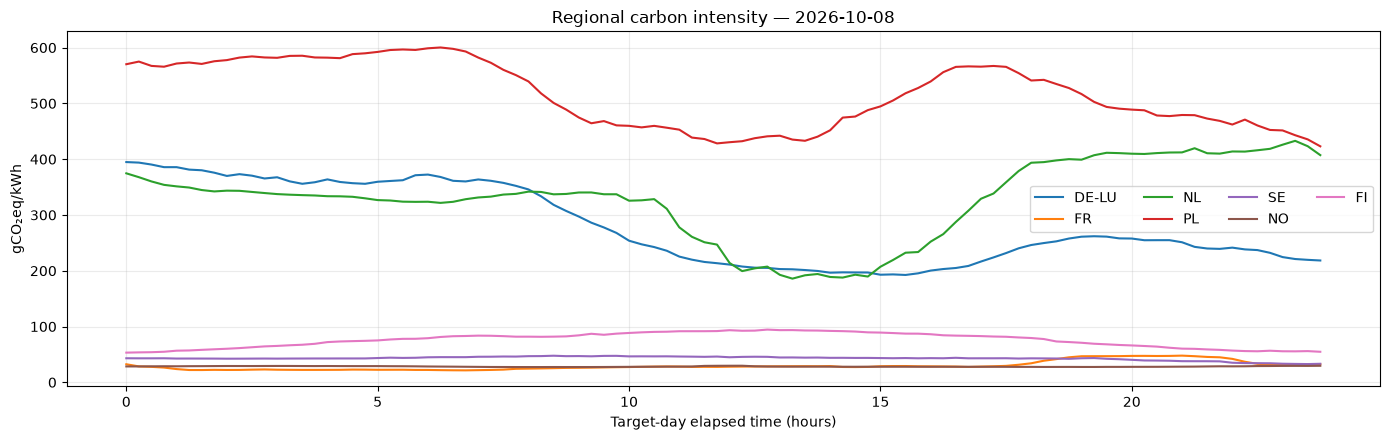

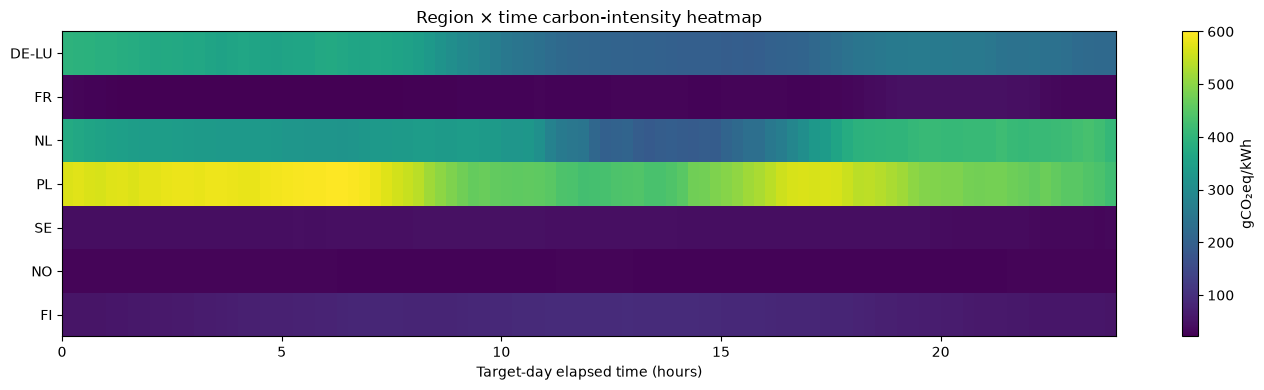

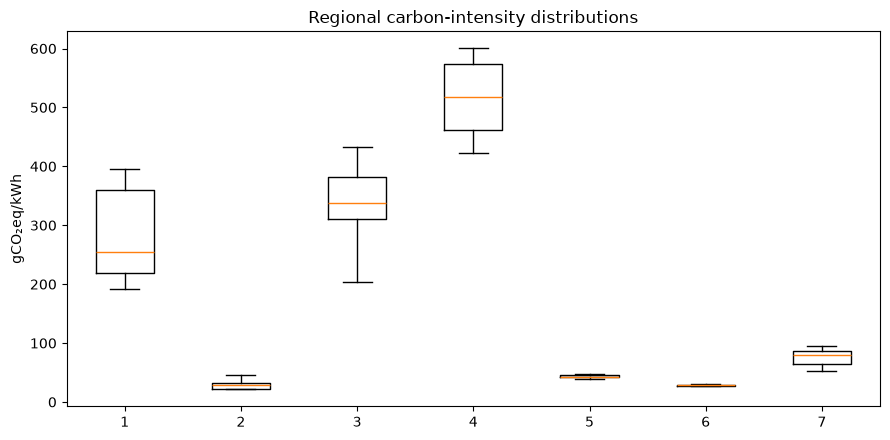

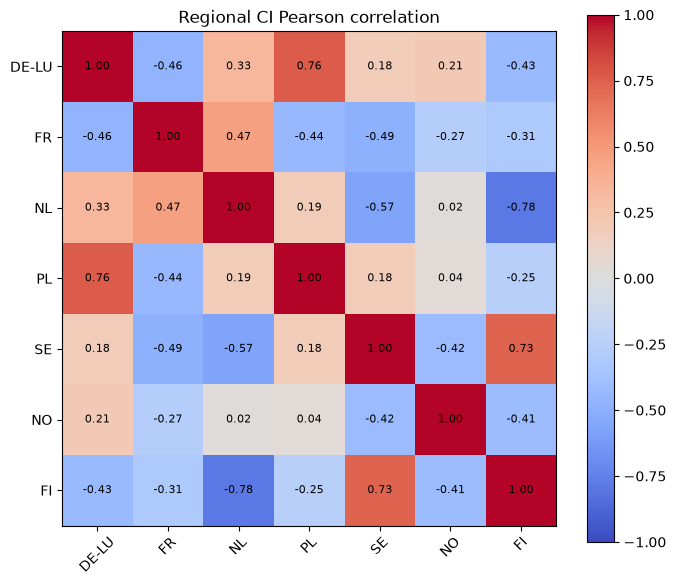

In [5]:
def finish_figure(name):
    plt.tight_layout()
    if EXPORT_FIGURES:
        plt.savefig(OUTPUT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

regional_stats = pd.DataFrame({"mean_gCO2eq_kWh": ci_day.mean(), "std_gCO2eq_kWh": ci_day.std(),
    "cv_pct": 100 * ci_day.std() / ci_day.mean().replace(0, np.nan),
    "min_gCO2eq_kWh": ci_day.min(), "p05_gCO2eq_kWh": ci_day.quantile(.05),
    "median_gCO2eq_kWh": ci_day.median(), "p95_gCO2eq_kWh": ci_day.quantile(.95),
    "max_gCO2eq_kWh": ci_day.max()}).sort_values("mean_gCO2eq_kWh")
pearson_corr, spearman_corr = ci_day.corr(), ci_day.corr(method="spearman")
display(regional_stats)
fig, ax = plt.subplots(figsize=(14, 4.5))
for region in regions:
    ax.plot(np.arange(SLOTS_PER_DAY)*SLOT_HOURS, ci_day[region], label=region)
ax.set(xlabel="Target-day elapsed time (hours)", ylabel="gCO₂eq/kWh", title=f"Regional carbon intensity — {DEMO_DATE}")
ax.legend(ncol=4); ax.grid(alpha=.25)
finish_figure("01_regional_ci_profiles")
fig, ax = plt.subplots(figsize=(14, 4))
im = ax.imshow(ci_day.to_numpy().T, aspect="auto", extent=[0,24,len(regions)-.5,-.5])
ax.set_yticks(range(len(regions))); ax.set_yticklabels(regions)
ax.set(xlabel="Target-day elapsed time (hours)", title="Region × time carbon-intensity heatmap")
fig.colorbar(im, ax=ax, label="gCO₂eq/kWh")
finish_figure("02_regional_ci_heatmap")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([ci_day[r].to_numpy() for r in regions], label=regions, showfliers=False)
ax.set(ylabel="gCO₂eq/kWh", title="Regional carbon-intensity distributions")
finish_figure("03_regional_ci_distributions")
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(pearson_corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(regions))); ax.set_xticklabels(regions, rotation=45)
ax.set_yticks(range(len(regions))); ax.set_yticklabels(regions)
for i in range(len(regions)):
    for j in range(len(regions)):
        ax.text(j, i, f"{pearson_corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Regional CI Pearson correlation")
fig.colorbar(im, ax=ax)
finish_figure("04_ci_pearson_correlation")

## 5. Regional infrastructure configuration

One independent hypothetical data center is evaluated in each region. Defaults are identical to isolate the carbon-signal effect; overrides are explicit and reported. There is no interregional capacity pooling, migration, or network penalty in this temporal-only experiment.

In [6]:
dc_config = pd.DataFrame([{"region": r,
    "power_capacity_kw": float(DC_OVERRIDES.get(r, {}).get("power_capacity_kw", P_MAX_KW)),
    "max_concurrent_jobs": int(DC_OVERRIDES.get(r, {}).get("max_concurrent_jobs", MAX_CONCURRENT_JOBS))}
    for r in regions]).set_index("region")
if (dc_config["power_capacity_kw"] <= 0).any() or (dc_config["max_concurrent_jobs"] < 1).any():
    raise ValueError("Regional power capacity and concurrency must be positive.")
display(dc_config)

,power_capacity_kw,max_concurrent_jobs
region,,
DE-LU,500.0000,60
FR,500.0000,60
NL,500.0000,60
PL,500.0000,60
SE,500.0000,60
NO,500.0000,60
FI,500.0000,60


## 6. Generate common flexible workloads

The original 48-hour release model is retained. Task durations and powers follow the configured discrete distributions; deadlines are sampled 4–12 hours after release and cannot be shorter than execution duration. A job is non-preemptive with constant power. The identical generated task table is reused across regions for each date/seed pair. Power is never reduced to fit a capacity-sensitivity scenario.

,task_id,release_slot,duration_slots,duration_hours,power_kw,deadline_window_slots,deadline_after_release_hours,deadline_slot
0,J318,0,12,3.0000,6.0000,27,6.7500,27
1,J728,0,4,1.0000,4.0000,35,8.7500,35
2,J760,0,8,2.0000,3.0000,29,7.2500,29
3,J789,0,12,3.0000,6.0000,40,10.0000,40
4,J821,0,4,1.0000,3.0000,34,8.5000,34
5,J005,1,4,1.0000,8.0000,35,8.7500,36
6,J251,1,12,3.0000,4.0000,40,10.0000,41
7,J345,1,12,3.0000,5.0000,20,5.0000,21
8,J552,1,4,1.0000,6.0000,26,6.5000,27
9,J713,1,12,3.0000,7.0000,25,6.2500,26


,duration_hours,power_kw,deadline_after_release_hours
count,900.0000,900.0000,900.0000
mean,2.2811,5.6422,8.0431
std,1.0104,1.4670,2.3394
min,1.0000,3.0000,4.0000
25%,1.0000,4.7500,6.1875
50%,2.0000,6.0000,8.0000
75%,3.0000,7.0000,10.0000
max,4.0000,8.0000,12.0000


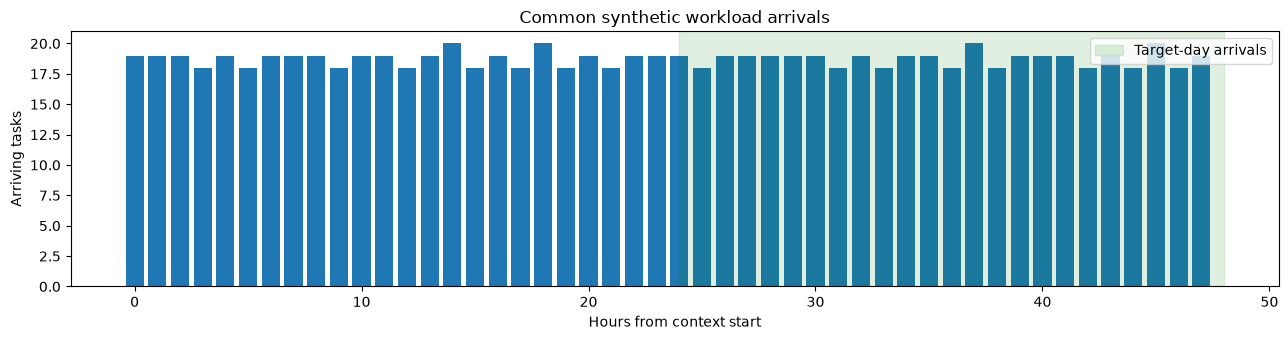

In [7]:
import numpy as np
import pandas as pd


def generate_workload(
    n_slots: int = 2 * SLOTS_PER_DAY,
    n_jobs: int = N_JOBS,
    seed: int = BASE_SEED,
    p_max_kw: float = P_MAX_KW,
    max_concurrent_jobs: int = MAX_CONCURRENT_JOBS,
    min_deadline_hours: float = MIN_DEADLINE_HOURS,
    max_deadline_hours: float = MAX_DEADLINE_HOURS,
) -> pd.DataFrame:
    """Generate jobs over the preceding and target days; deadlines may extend into day three.

    ``n_slots`` defines the release window (normally 192 slots). The 288-slot
    scheduling horizon is supplied separately through the carbon-intensity profile.
    """
    if n_slots < 1:
        raise ValueError("n_slots must be positive.")
    if n_jobs < 1:
        raise ValueError("n_jobs must be positive.")
    if p_max_kw < 3:
        raise ValueError("p_max_kw must be at least 3 kW.")
    if max_concurrent_jobs < 1:
        raise ValueError("max_concurrent_jobs must be positive.")
    if min_deadline_hours <= 0 or max_deadline_hours < min_deadline_hours:
        raise ValueError("Deadline-window bounds must satisfy 0 < min_deadline_hours <= max_deadline_hours.")

    rng = np.random.default_rng(seed)
    durations = rng.choice(
        DURATION_VALUES,
        size=n_jobs,
        p=DURATION_PROBABILITIES,
    ).astype(int)
    powers = rng.choice(
        POWER_VALUES_KW,
        size=n_jobs,
        p=POWER_PROBABILITIES,
    ).astype(float)
    # Keep powers fixed across capacity scenarios; baseline admission reports overload.

    # Stratified random release times spread jobs across the preceding and target days.
    # Explicitly include the first and last slots when there are at least two jobs.
    if n_jobs == 1:
        release_slots = np.array([int(rng.integers(0, n_slots))], dtype=int)
    else:
        positions = (np.arange(n_jobs) + rng.random(n_jobs)) * n_slots / n_jobs
        release_slots = np.floor(positions).astype(int)
        release_slots[0] = 0
        release_slots[-1] = n_slots - 1
        rng.shuffle(release_slots)
    release_slots = np.clip(release_slots, 0, n_slots - 1)

    min_window_slots = int(np.ceil(min_deadline_hours / SLOT_HOURS))
    max_window_slots = int(np.floor(max_deadline_hours / SLOT_HOURS))
    minimum_windows = np.maximum(durations, min_window_slots)
    if np.any(minimum_windows > max_window_slots):
        raise ValueError(
            "The maximum deadline window is shorter than at least one generated task. "
            "Increase max_deadline_hours or reduce maximum task duration."
        )
    deadline_window_slots = np.array([
        int(rng.integers(int(low), max_window_slots + 1))
        for low in minimum_windows
    ], dtype=int)
    deadline_slots = release_slots + deadline_window_slots

    tasks = pd.DataFrame({
        "task_id": [f"J{i + 1:03d}" for i in range(n_jobs)],
        "release_slot": release_slots,
        "duration_slots": durations,
        "duration_hours": durations * SLOT_HOURS,
        "power_kw": powers,
        "deadline_window_slots": deadline_window_slots,
        "deadline_after_release_hours": deadline_window_slots * SLOT_HOURS,
        "deadline_slot": deadline_slots,
    })
    return tasks.sort_values(["release_slot", "task_id"]).reset_index(drop=True)


def slot_to_clock(slot: int) -> str:
    """Format an absolute slot; label times after midnight with their day offset."""
    absolute_slot = int(slot)
    day_offset, slot_in_day = divmod(absolute_slot, SLOTS_PER_DAY)
    minutes = slot_in_day * int(round(SLOT_HOURS * 60))
    clock = f"{minutes // 60:02d}:{minutes % 60:02d}"
    return clock if day_offset == 0 else f"{clock} (+{day_offset}d)"



generated_tasks = generate_workload(n_slots=ARRIVAL_SLOTS, n_jobs=N_JOBS, seed=BASE_SEED)
if generated_tasks["deadline_slot"].max() > HORIZON_SLOTS:
    raise ValueError("Deadline settings exceed the 72-hour accounting horizon.")
display(generated_tasks.head(12))
display(generated_tasks[["duration_hours", "power_kw", "deadline_after_release_hours"]].describe())
fig, ax = plt.subplots(figsize=(13, 3.5))
release_counts = np.bincount(generated_tasks["release_slot"], minlength=ARRIVAL_SLOTS).reshape(48,4).sum(axis=1)
ax.bar(np.arange(48), release_counts)
ax.axvspan(24,48,alpha=.12,color="green",label="Target-day arrivals")
ax.set(xlabel="Hours from context start", ylabel="Arriving tasks", title="Common synthetic workload arrivals")
ax.legend()
finish_figure("05_workload_arrivals")

## 7. Temporal scheduling model

For a region, let \(a_j\), \(d_j\), \(p_j\), and \(b_j\) be release, duration, power, and deadline. Feasible integer starts are \(S_j=\{a_j,\ldots,\min(b_j-d_j,H-d_j)\}\), and \(y_{j,s}\) indicates a selected start. The MILP minimizes **full-horizon** estimated emissions:

\[
\min_y\sum_j\sum_{s\in S_j} y_{j,s}\frac{p_j\Delta t}{1000}
\sum_{t=s}^{s+d_j-1}\widehat{CI}_{r,t\mid o(j)}.
\]

\[
\sum_{s\in S_j}y_{j,s}=1,\quad
\sum_j\sum_{s\in S_j:s\leq t<s+d_j}p_jy_{j,s}\leq P_r^{\max},\quad
\sum_j\sum_{s\in S_j:s\leq t<s+d_j}y_{j,s}\leq K_r^{\max},\quad y_{j,s}\in\{0,1\}.
\]

For the rolling policy, \(o(j)=\lfloor a_j/u\rfloor u\) is the latest issue slot at or before release, with update interval \(u\). Each task uses its own complete forecast issued at \(o(j)\) for every feasible start. Later forecast revisions never replace an earlier task's objective coefficients. The retrospective benchmark uses observed intensity. All schedules are evaluated using observed intensity. Primary target-day metrics include only energy/emissions overlapping slots [96, 192). Full-horizon metrics cover [0, 288), so boundary displacement is visible. Full-horizon task energy is invariant for the same accepted set; middle-day energy need not be.

## 8. Carbon-unaware earliest-feasible baseline

The baseline processes tasks by release and identifier, allocating the earliest resource-feasible start before each deadline. Tasks it cannot place are logged and excluded from every policy in that scenario. This common-subset protocol isolates scheduling differences and prevents inconsistent completed-work comparisons. Exclusions remain distinct from deadline violations within accepted schedules.

In [8]:
def schedule_earliest_feasible(
    tasks: pd.DataFrame,
    n_slots: int,
    p_max_kw: float,
    max_concurrent_jobs: int | None,
) -> tuple[dict[str, int], pd.DataFrame]:
    """Schedule feasible jobs earliest-first and return a report for jobs that cannot be placed."""
    power_load = np.zeros(n_slots, dtype=float)
    job_load = np.zeros(n_slots, dtype=int)
    starts: dict[str, int] = {}
    violations: list[dict] = []

    ordered = tasks.sort_values(["release_slot", "task_id"])
    for row in ordered.itertuples(index=False):
        task_id = str(row.task_id)
        earliest = max(0, int(row.release_slot))
        duration = int(row.duration_slots)
        deadline = int(row.deadline_slot)
        power = float(row.power_kw)
        latest_start = min(deadline - duration, n_slots - duration)
        chosen = None
        failure_reason = None

        if power > p_max_kw + 1e-9:
            failure_reason = "task_power_exceeds_capacity"
        elif latest_start < earliest:
            failure_reason = "no_start_window_before_deadline_within_horizon"
        else:
            for start in range(earliest, latest_start + 1):
                end = start + duration
                power_ok = np.all(power_load[start:end] + power <= p_max_kw + 1e-9)
                concurrency_ok = (
                    True if max_concurrent_jobs is None
                    else np.all(job_load[start:end] + 1 <= max_concurrent_jobs)
                )
                if power_ok and concurrency_ok:
                    chosen = start
                    break
            if chosen is None:
                failure_reason = "resource_capacity_or_concurrency_conflict_before_deadline"

        if chosen is None:
            violations.append({
                "task_id": task_id,
                "release_slot": earliest,
                "duration_slots": duration,
                "power_kw": power,
                "deadline_slot": deadline,
                "failure_reason": failure_reason,
            })
            continue

        end = chosen + duration
        power_load[chosen:end] += power
        job_load[chosen:end] += 1
        starts[task_id] = int(chosen)

    columns = ["task_id", "release_slot", "duration_slots", "power_kw", "deadline_slot", "failure_reason"]
    return starts, pd.DataFrame(violations, columns=columns)

## 9. MILP optimization and transparent solver reporting

Every solve records region, date, workload seed, experiment, capacity multiplier, status, objective bound, achieved gap, and returned-schedule source. A time-limited feasible solution is not called an exact oracle. The feasible baseline is retained if the solver has no incumbent or returns a worse objective. The observed-CI solve may also retain the rolling-forecast schedule if it has lower observed full-horizon emissions. These selections are explicitly logged and do not imply optimality.

In [9]:
def schedule_objective(tasks, starts, ci, job_forecasts=None):
    return float(sum(row.power_kw * SLOT_HOURS * np.sum((job_forecasts[str(row.task_id)] if job_forecasts is not None else ci)[int(starts[row.task_id]):int(starts[row.task_id])+int(row.duration_slots)]) / 1000
                     for row in tasks.itertuples(index=False)))

def optimize_schedule_milp(tasks, objective_ci, p_max_kw, max_concurrent_jobs,
                           reference_starts, context, extra_reference=None, job_forecasts=None):
    ci = np.asarray(objective_ci, dtype=float)
    if not np.isfinite(ci).all() or len(ci) != HORIZON_SLOTS:
        raise ValueError("Optimization requires a complete 288-slot carbon trace.")
    records = list(tasks.itertuples(index=False))
    candidates, costs = [], []
    rr, cc, vv = [], [], []
    for j, row in enumerate(records):
        for start in range(int(row.release_slot), min(int(row.deadline_slot)-int(row.duration_slots),len(ci)-int(row.duration_slots))+1):
            end = start + int(row.duration_slots)
            k = len(candidates)
            candidates.append((j, start))
            objective_values = job_forecasts[str(row.task_id)] if job_forecasts is not None else ci
            if not np.isfinite(objective_values[start:end]).all():
                raise ValueError(f"Missing forecast coverage for task {row.task_id} at {start}.")
            costs.append(row.power_kw*SLOT_HOURS*np.sum(objective_values[start:end])/1000)
            rr.append(j); cc.append(k); vv.append(1.)
            for t in range(start,end):
                rr.extend([len(records)+t,len(records)+len(ci)+t])
                cc.extend([k,k]); vv.extend([row.power_kw,1.])
    if not candidates:
        raise ValueError("No MILP variables; check accepted workload and deadlines.")
    n_rows = len(records) + 2*len(ci)
    matrix = coo_matrix((vv,(rr,cc)),shape=(n_rows,len(candidates))).tocsr()
    lower = np.zeros(n_rows)
    upper = np.r_[np.ones(len(records)),np.full(len(ci),p_max_kw),np.full(len(ci),max_concurrent_jobs)]
    lower[:len(records)] = 1
    result = milp(c=np.asarray(costs),integrality=np.ones(len(costs),dtype=np.int8),
        bounds=Bounds(np.zeros(len(costs)),np.ones(len(costs))),
        constraints=LinearConstraint(matrix,lower,upper),
        options={"time_limit":float(MILP_TIME_LIMIT_SECONDS),"mip_rel_gap":float(MILP_RELATIVE_GAP)})
    choices = [("baseline_reference",dict(reference_starts))]
    if extra_reference is not None:
        choices.append(("forecast_reference",dict(extra_reference)))
    if result.x is not None:
        selected = np.flatnonzero(result.x > .5)
        starts = {str(records[candidates[k][0]].task_id):candidates[k][1] for k in selected}
        if len(selected) != len(records) or len(starts) != len(records):
            raise AssertionError("MILP returned incomplete/duplicate task assignments.")
        # Validate any incumbent before comparing its objective with references.
        evaluate_schedule(tasks,starts,ci,p_max_kw,max_concurrent_jobs,0,len(ci))
        choices.insert(0,("milp_incumbent",starts))
    source, best = min(choices,key=lambda pair:schedule_objective(tasks,pair[1],ci,job_forecasts))
    achieved_objective = schedule_objective(tasks,best,ci,job_forecasts)
    bound = getattr(result,"mip_dual_bound",np.nan)
    gap = getattr(result,"mip_gap",np.nan)
    bound = np.nan if bound is None else float(bound)
    gap = np.nan if gap is None else float(gap)
    info = {**context,"n_jobs":len(records),"candidate_variables":len(costs),
        "time_limit_seconds":MILP_TIME_LIMIT_SECONDS,"status":int(result.status),
        "solver_success":bool(result.success),"solver_message":str(result.message),
        "solver_incumbent_objective_kg":float(result.fun) if result.fun is not None else np.nan,
        "solver_mip_gap":gap,"dual_bound_kg":bound,"selected_source":source,
        "used_reference":source!="milp_incumbent","no_solver_incumbent":result.x is None,
        "selected_objective_kg":achieved_objective,
        "selected_gap_to_bound":max(0.,(achieved_objective-bound)/abs(achieved_objective))
            if np.isfinite(bound) and abs(achieved_objective)>1e-12 else np.nan}
    MILP_SOLVE_LOG.append(info)
    if not result.success:
        warnings.warn(f"{context['region']} {context['policy']}: {result.message}; selected {source}. Inspect solver log.")
    return best, info

## 10. Evaluation and common-scenario runner

Each schedule is validated across all 72 hours for unique assignment, releases, deadlines, power and concurrency. Target-day and full-horizon energy, emissions, weighted carbon intensity, waiting time, utilization, admission/exclusion, and solver provenance are retained. All regional workloads are independent copies of the same generated table; no job changes its region.

In [10]:
def evaluate_schedule(
    tasks: pd.DataFrame,
    starts: dict[str, int],
    actual_ci: np.ndarray,
    p_max_kw: float,
    max_concurrent_jobs: int | None,
    metric_start_slot: int = SLOTS_PER_DAY,
    metric_end_slot: int = 2 * SLOTS_PER_DAY,
) -> tuple[dict, pd.DataFrame, np.ndarray, np.ndarray]:

    ci = np.asarray(actual_ci, dtype=float)
    n_slots = len(ci)

    power_load = np.zeros(n_slots, dtype=float)
    job_load = np.zeros(n_slots, dtype=int)

    schedule_rows = []
    total_energy_kwh = 0.0
    total_emissions_kg = 0.0

    deadline_violations = 0
    release_violations = 0

    task_lookup = tasks.set_index("task_id")

    for task_id, start_value in starts.items():
        row = task_lookup.loc[task_id]

        start = int(start_value)
        duration = int(row["duration_slots"])
        end = start + duration
        power = float(row["power_kw"])

        # Validate execution against the complete 72-hour horizon.
        if start < 0 or end > n_slots:
            raise AssertionError(
                f"Task {task_id} lies outside the scheduling horizon."
            )

        if not np.isfinite(ci[start:end]).all():
            raise AssertionError(
                f"Task {task_id} overlaps missing carbon-intensity data."
            )

        # Calculate the overlap with the target 24-hour interval.
        metric_start = max(start, metric_start_slot)
        metric_end = min(end, metric_end_slot)
        metric_slots = max(0, metric_end - metric_start)

        # Energy and emissions are measured only within the target interval.
        energy_kwh = power * metric_slots * SLOT_HOURS

        emissions_kg = (
            power * SLOT_HOURS
            * float(ci[metric_start:metric_end].sum())
            / 1000.0
            if metric_slots > 0 else 0.0
        )

        total_energy_kwh += energy_kwh
        total_emissions_kg += emissions_kg

        # Track resource consumption over the complete 72-hour horizon.
        power_load[start:end] += power
        job_load[start:end] += 1

        if start < int(row["release_slot"]):
            release_violations += 1

        if end > int(row["deadline_slot"]):
            deadline_violations += 1

        schedule_rows.append({
            "task_id": task_id,
            "release_slot": int(row["release_slot"]),
            "start_slot": start,
            "end_slot": end,
            "duration_slots": duration,
            "duration_hours": duration * SLOT_HOURS,
            "power_kw": power,
            "deadline_slot": int(row["deadline_slot"]),
            "waiting_hours": (
                start - int(row["release_slot"])
            ) * SLOT_HOURS,
            "deadline_slack_hours": (
                int(row["deadline_slot"]) - end
            ) * SLOT_HOURS,
            "energy_kwh": energy_kwh,
            "emissions_kgCO2eq": emissions_kg,
        })

    # Validate resource constraints over all 72 hours.
    peak_power = float(power_load.max(initial=0.0))
    peak_jobs = int(job_load.max(initial=0))

    power_violation_slots = int(
        np.sum(power_load > p_max_kw + 1e-8)
    )

    concurrency_violation_slots = (
        0 if max_concurrent_jobs is None
        else int(np.sum(job_load > max_concurrent_jobs))
    )

    # Carbon intensity weighted by energy consumed in the target interval.
    weighted_ci = (
        total_emissions_kg * 1000.0 / total_energy_kwh
        if total_energy_kwh > 0 else np.nan
    )

    target_window_hours = (
        metric_end_slot - metric_start_slot
    ) * SLOT_HOURS

    available_capacity_kwh = p_max_kw * target_window_hours

    metrics = {
        "metric_window_start_slot": metric_start_slot,
        "metric_window_end_slot": metric_end_slot,
        "energy_kwh": total_energy_kwh,
        "emissions_kgCO2eq": total_emissions_kg,
        "weighted_CI_gCO2eq_per_kWh": weighted_ci,
        "mean_wait_hours": (
            float(np.mean([r["waiting_hours"] for r in schedule_rows]))
            if schedule_rows else 0.0
        ),
        "max_wait_hours": (
            float(np.max([r["waiting_hours"] for r in schedule_rows]))
            if schedule_rows else 0.0
        ),
        "deadline_violations": deadline_violations,
        "release_violations": release_violations,
        "peak_power_kw": peak_power,
        "peak_concurrent_jobs": peak_jobs,
        "power_violation_slots": power_violation_slots,
        "concurrency_violation_slots": concurrency_violation_slots,
        "capacity_energy_utilization_pct": (
            100.0 * total_energy_kwh / available_capacity_kwh
            if available_capacity_kwh else np.nan
        ),
    }

    schedule_table = (
        pd.DataFrame(schedule_rows, columns=["task_id", "release_slot", "start_slot", "end_slot",
            "duration_slots", "duration_hours", "power_kw", "deadline_slot", "waiting_hours",
            "deadline_slack_hours", "energy_kwh", "emissions_kgCO2eq"])
        .sort_values(["start_slot", "task_id"])
        .reset_index(drop=True)
    )

    violations = [
        deadline_violations,
        release_violations,
        power_violation_slots,
        concurrency_violation_slots,
    ]

    if any(violations):
        raise AssertionError(
            f"Schedule validation failed. Violation counts: {violations}"
        )

    return metrics, schedule_table, power_load, job_load

SCENARIO_CACHE = {}
EXCLUSION_FRAMES = []
def run_scenario(region, date_string, seed=BASE_SEED, capacity_scale=1.0, experiment="demo"):
    key = (region,date_string,int(seed),float(capacity_scale))
    if key in SCENARIO_CACHE:
        return SCENARIO_CACHE[key]
    actual_ci = get_three_day_ci(region,date_string)
    forecast_bundle = get_rolling_forecast_bundle(region,date_string)
    forecast_ci = forecast_bundle["plot_profile"]
    cap = float(dc_config.loc[region,"power_capacity_kw"])*capacity_scale
    concurrency = max(1,int(np.floor(dc_config.loc[region,"max_concurrent_jobs"]*capacity_scale)))
    generated = generate_workload(n_slots=ARRIVAL_SLOTS,n_jobs=N_JOBS,seed=int(seed))
    if generated["deadline_slot"].max() > len(actual_ci):
        raise ValueError("Task deadlines exceed the accounting horizon.")
    baseline, exclusions = schedule_earliest_feasible(generated,len(actual_ci),cap,concurrency)
    accepted = generated[generated["task_id"].isin(baseline)].copy().reset_index(drop=True)
    context = {"region":region,"date":date_string,"workload_seed":int(seed),
               "capacity_scale":capacity_scale,"experiment":experiment}
    if not exclusions.empty:
        EXCLUSION_FRAMES.append(exclusions.assign(**context))
    if len(accepted):
        job_forecasts = forecasts_at_task_release(accepted,forecast_bundle)
        forecast, forecast_info = optimize_schedule_milp(accepted,forecast_ci,cap,concurrency,baseline,
                         {**context,"policy":POLICY_FORECAST},job_forecasts=job_forecasts)
        oracle, oracle_info = optimize_schedule_milp(accepted,actual_ci,cap,concurrency,baseline,
                                      {**context,"policy":POLICY_ORACLE},extra_reference=forecast)
    else:
        forecast, oracle = {}, {}
        forecast_info = oracle_info = {"selected_source":"no_accepted_jobs","solver_success":False,
                                      "status":np.nan,"solver_mip_gap":np.nan,"used_reference":True}
    assignments = {POLICY_BASELINE:baseline,POLICY_FORECAST:forecast,POLICY_ORACLE:oracle}
    rows, schedules, loads = [], {}, {}
    expected_energy = float((accepted["power_kw"]*accepted["duration_slots"]*SLOT_HOURS).sum())
    for policy, starts in assignments.items():
        if set(starts) != set(accepted["task_id"]):
            raise AssertionError("Policies do not schedule identical accepted task sets.")
        target, table, load, job_load = evaluate_schedule(accepted,starts,actual_ci,cap,concurrency,
                                                     TARGET_START_SLOT,TARGET_END_SLOT)
        full, _, _, _ = evaluate_schedule(accepted,starts,actual_ci,cap,concurrency,0,HORIZON_SLOTS)
        assert np.isclose(full["energy_kwh"],expected_energy)
        info = ({"selected_source":"earliest_feasible","solver_success":False,"status":np.nan,
                 "solver_mip_gap":np.nan,"used_reference":False} if policy==POLICY_BASELINE
                else forecast_info if policy==POLICY_FORECAST else oracle_info)
        rows.append({**context,"policy":policy,"p_max_kw":cap,"max_concurrent_jobs":concurrency,
            "generated_jobs":len(generated),"scheduled_jobs":len(accepted),"excluded_jobs":len(exclusions),
            "admission_rate_pct":100*len(accepted)/len(generated),
            "baseline_exclusion_rate_pct":100*len(exclusions)/len(generated),**target,
            "full_horizon_energy_kwh":full["energy_kwh"],
            "full_horizon_emissions_kgCO2eq":full["emissions_kgCO2eq"],
            "outside_target_energy_kwh":full["energy_kwh"]-target["energy_kwh"],
            "outside_target_emissions_kgCO2eq":full["emissions_kgCO2eq"]-target["emissions_kgCO2eq"],
            "selected_source":info["selected_source"],"solver_success":info["solver_success"],
            "solver_status":info["status"],"solver_mip_gap":info["solver_mip_gap"],
            "used_reference":info["used_reference"]})
        if policy == POLICY_FORECAST:
            table["forecast_issue_slot"] = (table["release_slot"]//FORECAST_UPDATE_SLOTS)*FORECAST_UPDATE_SLOTS
            table["predicted_task_emissions_kgCO2eq"] = [
                row.power_kw*SLOT_HOURS*np.sum(forecast_bundle["bank"][int(row.forecast_issue_slot)][int(row.start_slot):int(row.end_slot)])/1000
                for row in table.itertuples(index=False)]
        schedules[policy], loads[policy] = table, load
    metrics = pd.DataFrame(rows)
    base = metrics.loc[metrics["policy"].eq(POLICY_BASELINE)].iloc[0]
    for prefix,col in [("target","emissions_kgCO2eq"),("full_horizon","full_horizon_emissions_kgCO2eq")]:
        metrics[prefix+"_savings_kg"] = base[col]-metrics[col]
        metrics[prefix+"_savings_pct"] = 100*(base[col]-metrics[col])/base[col] if base[col]>0 else np.nan
    result = {"metrics":metrics,"schedules":schedules,"loads":loads,"tasks":accepted,
        "generated_tasks":generated,"exclusions":exclusions,"actual_ci":actual_ci,
        "forecast_ci":forecast_ci,"forecast_bundle":forecast_bundle,"assignments":assignments}
    SCENARIO_CACHE[key] = result
    return result

# Estimate the maximum solve budget before the regional experiments.
print(f"Demonstration: {2*len(regions)} solves. Cached identical date/seed/capacity scenarios are reused.")

Demonstration: 14 solves. Cached identical date/seed/capacity scenarios are reused.


## 11. Run all regions and compare carbon savings

Every configured region is evaluated on the common demonstration date. Savings are relative to that region's own same-capacity baseline, not to another region. Percentage savings can be negative for the forecast policy. A decrease in target-day emissions alone may reflect boundary displacement; inspect full-horizon savings and target-day energy together.

In [11]:
demo_results = {}
for region in regions:
    print(f"Evaluating demonstration: {region}, {DEMO_DATE}")
    demo_results[region] = run_scenario(region,DEMO_DATE)
metrics_table = pd.concat([result["metrics"] for result in demo_results.values()],ignore_index=True)
savings_table = metrics_table[["region","policy","scheduled_jobs","excluded_jobs","energy_kwh",
    "emissions_kgCO2eq","target_savings_kg","target_savings_pct","full_horizon_energy_kwh",
    "full_horizon_emissions_kgCO2eq","full_horizon_savings_pct","selected_source","solver_mip_gap"]]
display(savings_table)

Evaluating demonstration: DE-LU, 2026-10-08
Evaluating demonstration: FR, 2026-10-08
Evaluating demonstration: NL, 2026-10-08
Evaluating demonstration: PL, 2026-10-08
Evaluating demonstration: SE, 2026-10-08
Evaluating demonstration: NO, 2026-10-08
Evaluating demonstration: FI, 2026-10-08


,region,policy,scheduled_jobs,excluded_jobs,energy_kwh,emissions_kgCO2eq,target_savings_kg,target_savings_pct,full_horizon_energy_kwh,full_horizon_emissions_kgCO2eq,full_horizon_savings_pct,selected_source,solver_mip_gap
0,DE-LU,Carbon-unaware baseline,900,0,"5,718.5000","1,606.3333",0.0000,0.0000,"11,540.0000","4,004.6542",0.0000,earliest_feasible,NaN
1,DE-LU,Rolling AR forecast MILP,900,0,"6,078.7500","1,657.4808",-51.1474,-3.1841,"11,540.0000","3,457.1233",13.6724,milp_incumbent,0.0000
2,DE-LU,Retrospective MILP benchmark,900,0,"5,749.5000","1,584.2684",22.0649,1.3736,"11,540.0000","3,370.1501",15.8442,milp_incumbent,0.0057
3,FR,Carbon-unaware baseline,900,0,"5,718.5000",170.4281,0.0000,0.0000,"11,540.0000",463.7210,0.0000,earliest_feasible,NaN
4,FR,Rolling AR forecast MILP,900,0,"5,242.7500",139.8877,30.5404,17.9198,"11,540.0000",413.2582,10.8822,milp_incumbent,0.0053
5,FR,Retrospective MILP benchmark,900,0,"5,806.5000",151.9287,18.4993,10.8546,"11,540.0000",388.9675,16.1204,milp_incumbent,0.0015
6,NL,Carbon-unaware baseline,900,0,"5,718.5000","1,876.1700",0.0000,0.0000,"11,540.0000","4,860.0275",0.0000,earliest_feasible,NaN
7,NL,Rolling AR forecast MILP,900,0,"5,772.7500","1,737.9679",138.2021,7.3662,"11,540.0000","4,392.9974",9.6096,milp_incumbent,0.0000
8,NL,Retrospective MILP benchmark,900,0,"5,847.5000","1,743.0674",133.1025,7.0944,"11,540.0000","4,125.2886",15.1180,milp_incumbent,0.0011
9,PL,Carbon-unaware baseline,900,0,"5,718.5000","2,959.9723",0.0000,0.0000,"11,540.0000","6,352.2699",0.0000,earliest_feasible,NaN


## 12. Validate all regional schedules

Assert complete common-task assignment, invariant full-horizon task energy, zero deadline/release/resource violations, and correct observed-CI accounting. Check that the retrospective returned schedule is no worse than both available references for the full-horizon observed objective. Middle-day ordering need not follow full-horizon ordering.

In [12]:
for region,result in demo_results.items():
    metrics = result["metrics"].set_index("policy")
    for col in ["deadline_violations","release_violations","power_violation_slots","concurrency_violation_slots"]:
        assert metrics[col].eq(0).all(), (region,col)
    assert np.allclose(metrics["full_horizon_energy_kwh"],metrics["full_horizon_energy_kwh"].iloc[0])
    assert np.allclose(metrics["energy_kwh"]+metrics["outside_target_energy_kwh"],metrics["full_horizon_energy_kwh"])
    assert np.allclose(metrics["emissions_kgCO2eq"]+metrics["outside_target_emissions_kgCO2eq"],
                       metrics["full_horizon_emissions_kgCO2eq"])
    oracle_em = metrics.loc[POLICY_ORACLE,"full_horizon_emissions_kgCO2eq"]
    assert oracle_em <= metrics.loc[POLICY_BASELINE,"full_horizon_emissions_kgCO2eq"]+1e-7
    assert oracle_em <= metrics.loc[POLICY_FORECAST,"full_horizon_emissions_kgCO2eq"]+1e-7
assert set(metrics_table["region"]) == set(regions)
print("Validation passed for all configured regions. Accepted schedules meet all modeled constraints.")

Validation passed for all configured regions. Accepted schedules meet all modeled constraints.


## 13. Visualize temporal allocation and policy outcomes

For each region, show observed/rolling traces and aggregate power over the complete context with the target day highlighted. The Gantt chart displays at most the configured number of tasks, selected from the baseline's target-day-overlapping tasks (or the first arrivals if none overlap); the same tasks appear for all policies. This avoids the unreadable full-workload Gantt in the spatial notebook. Complete task schedules are exported. The rolling curve shows the first update-block from each forecast for visual diagnostics; it is not the single cost trace used by the optimizer. Task costs use the complete forecast available at that task's release.

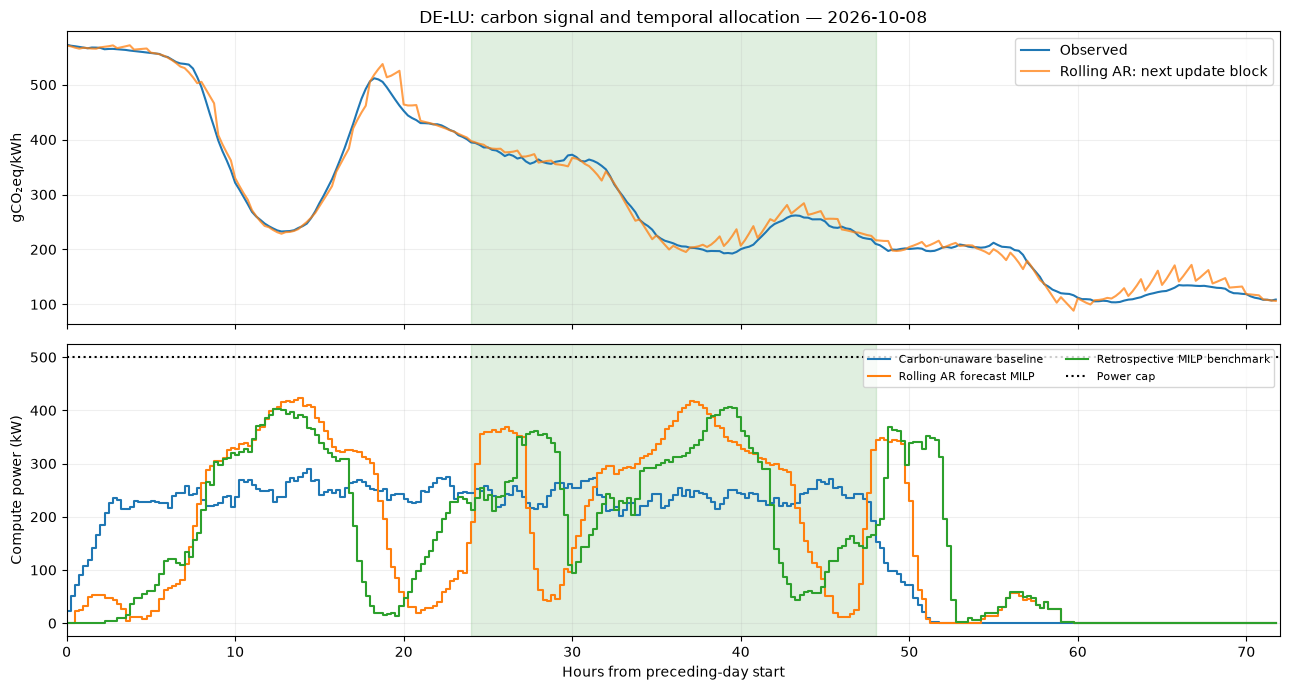

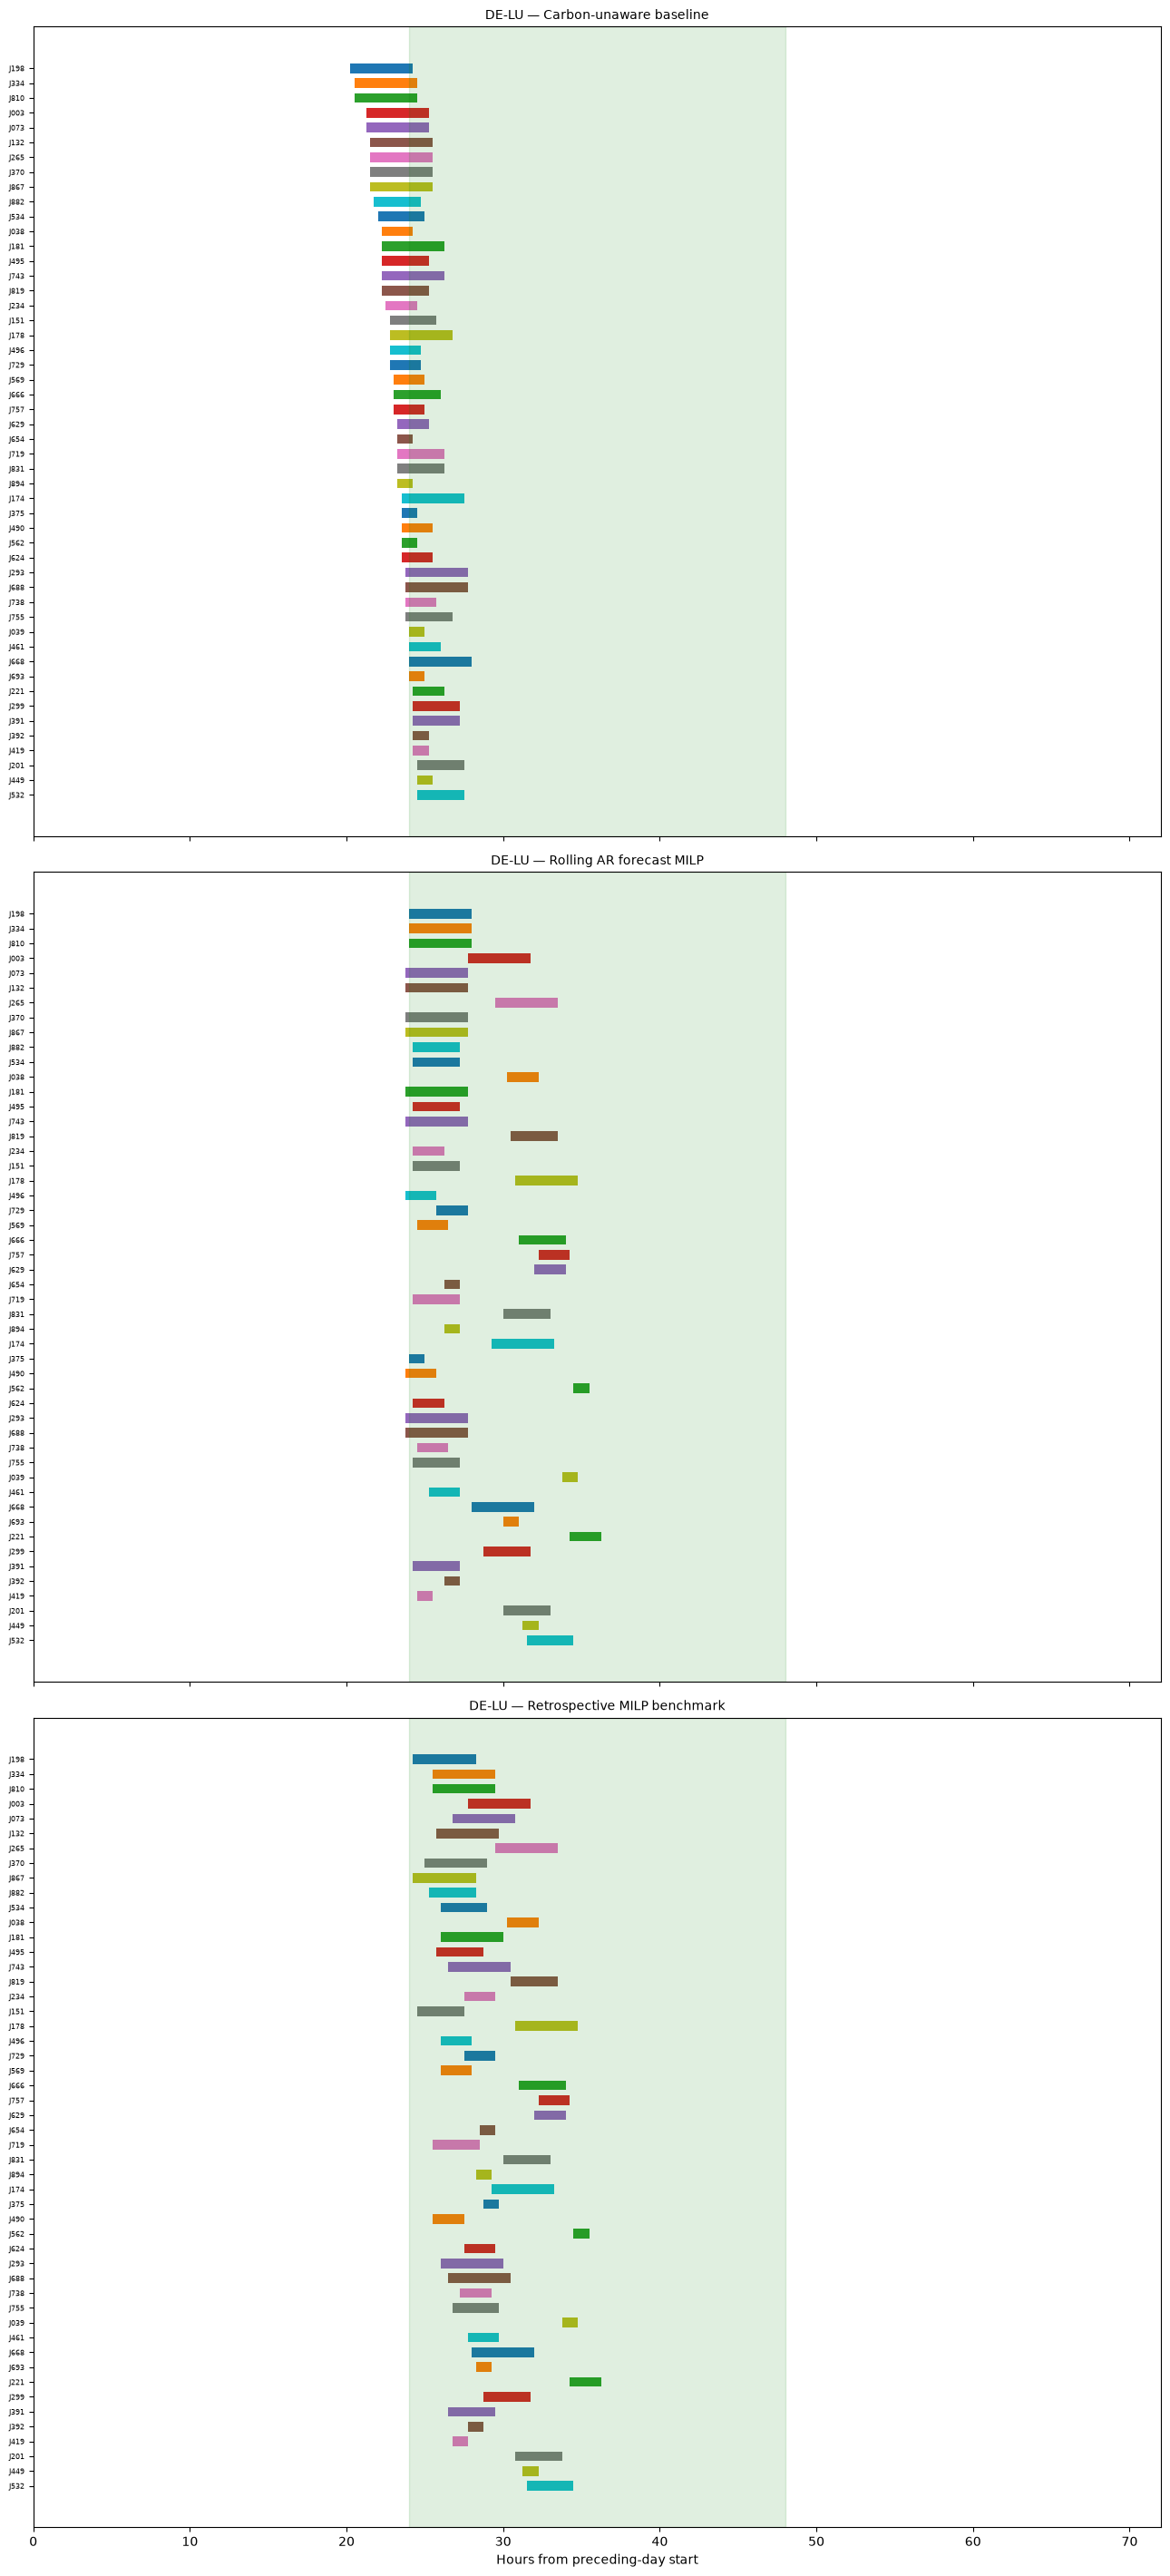

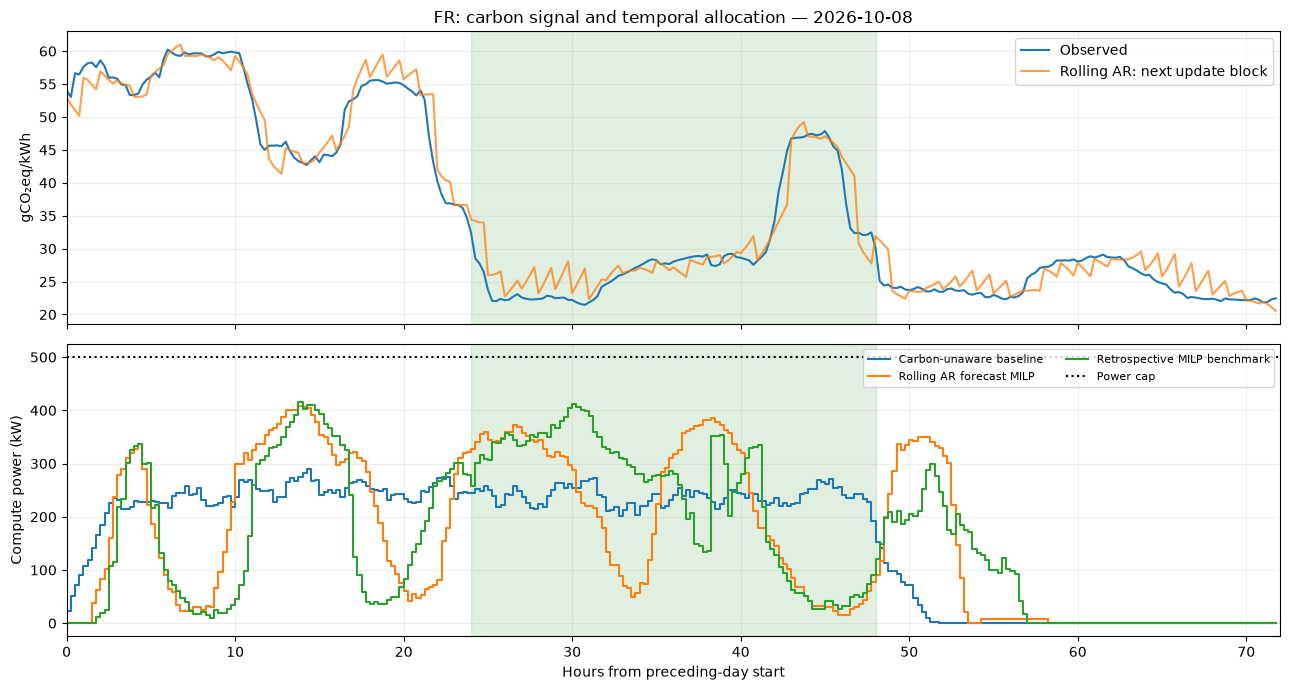

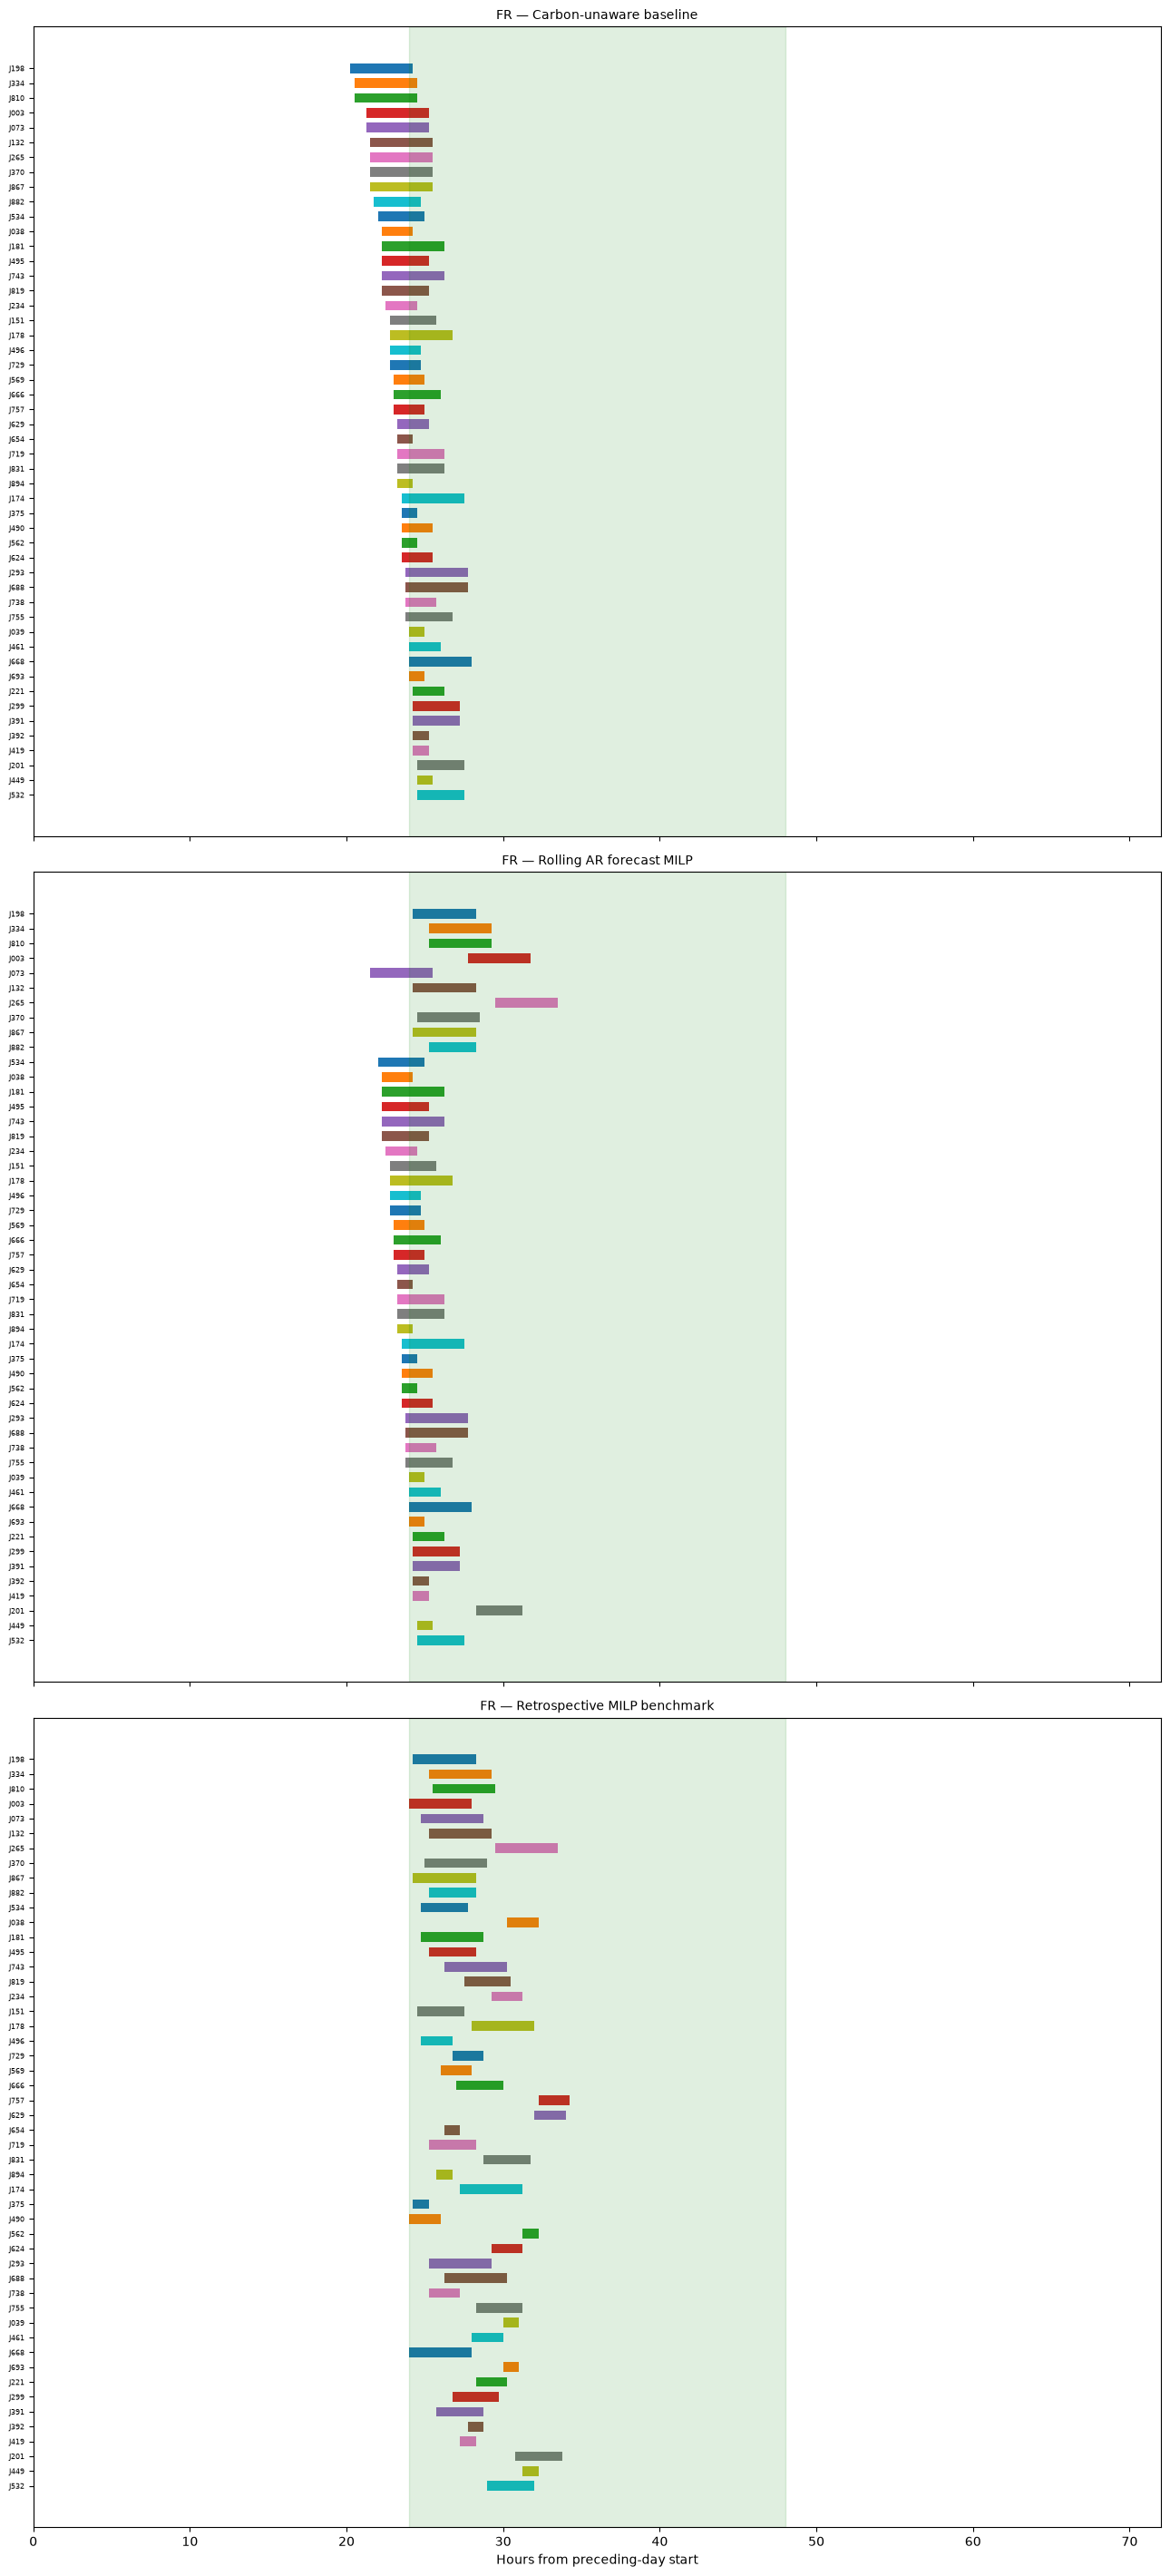

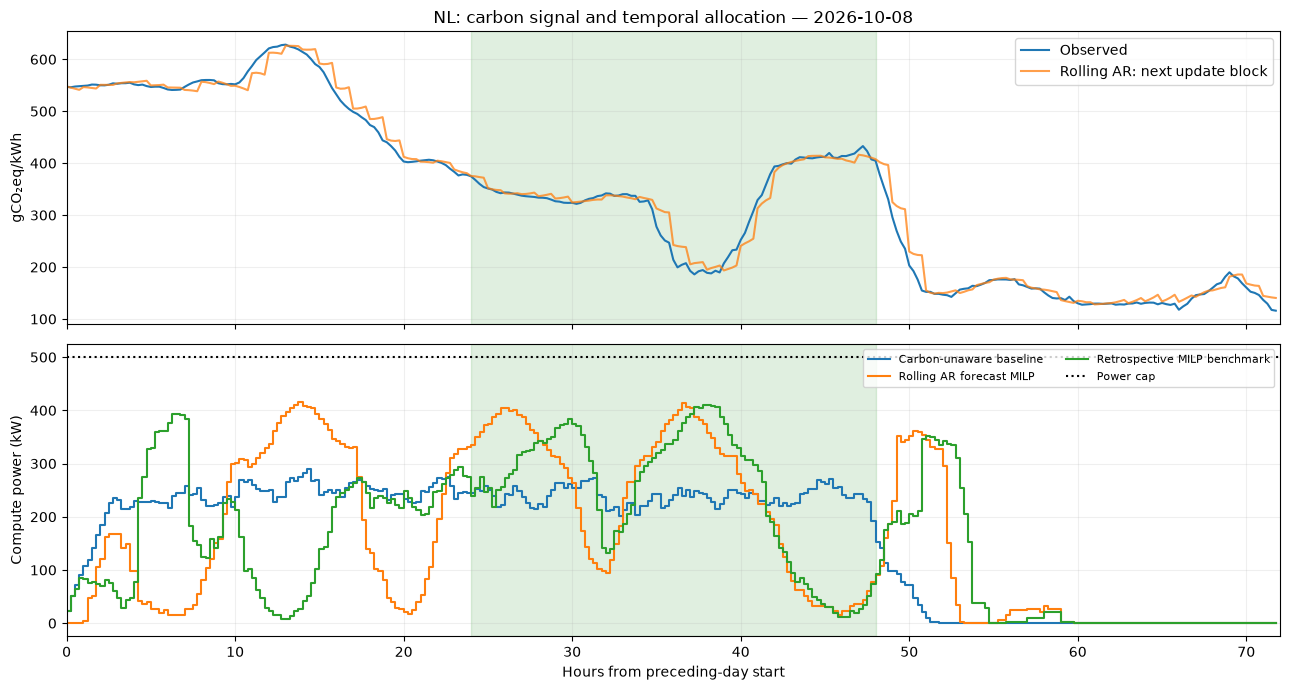

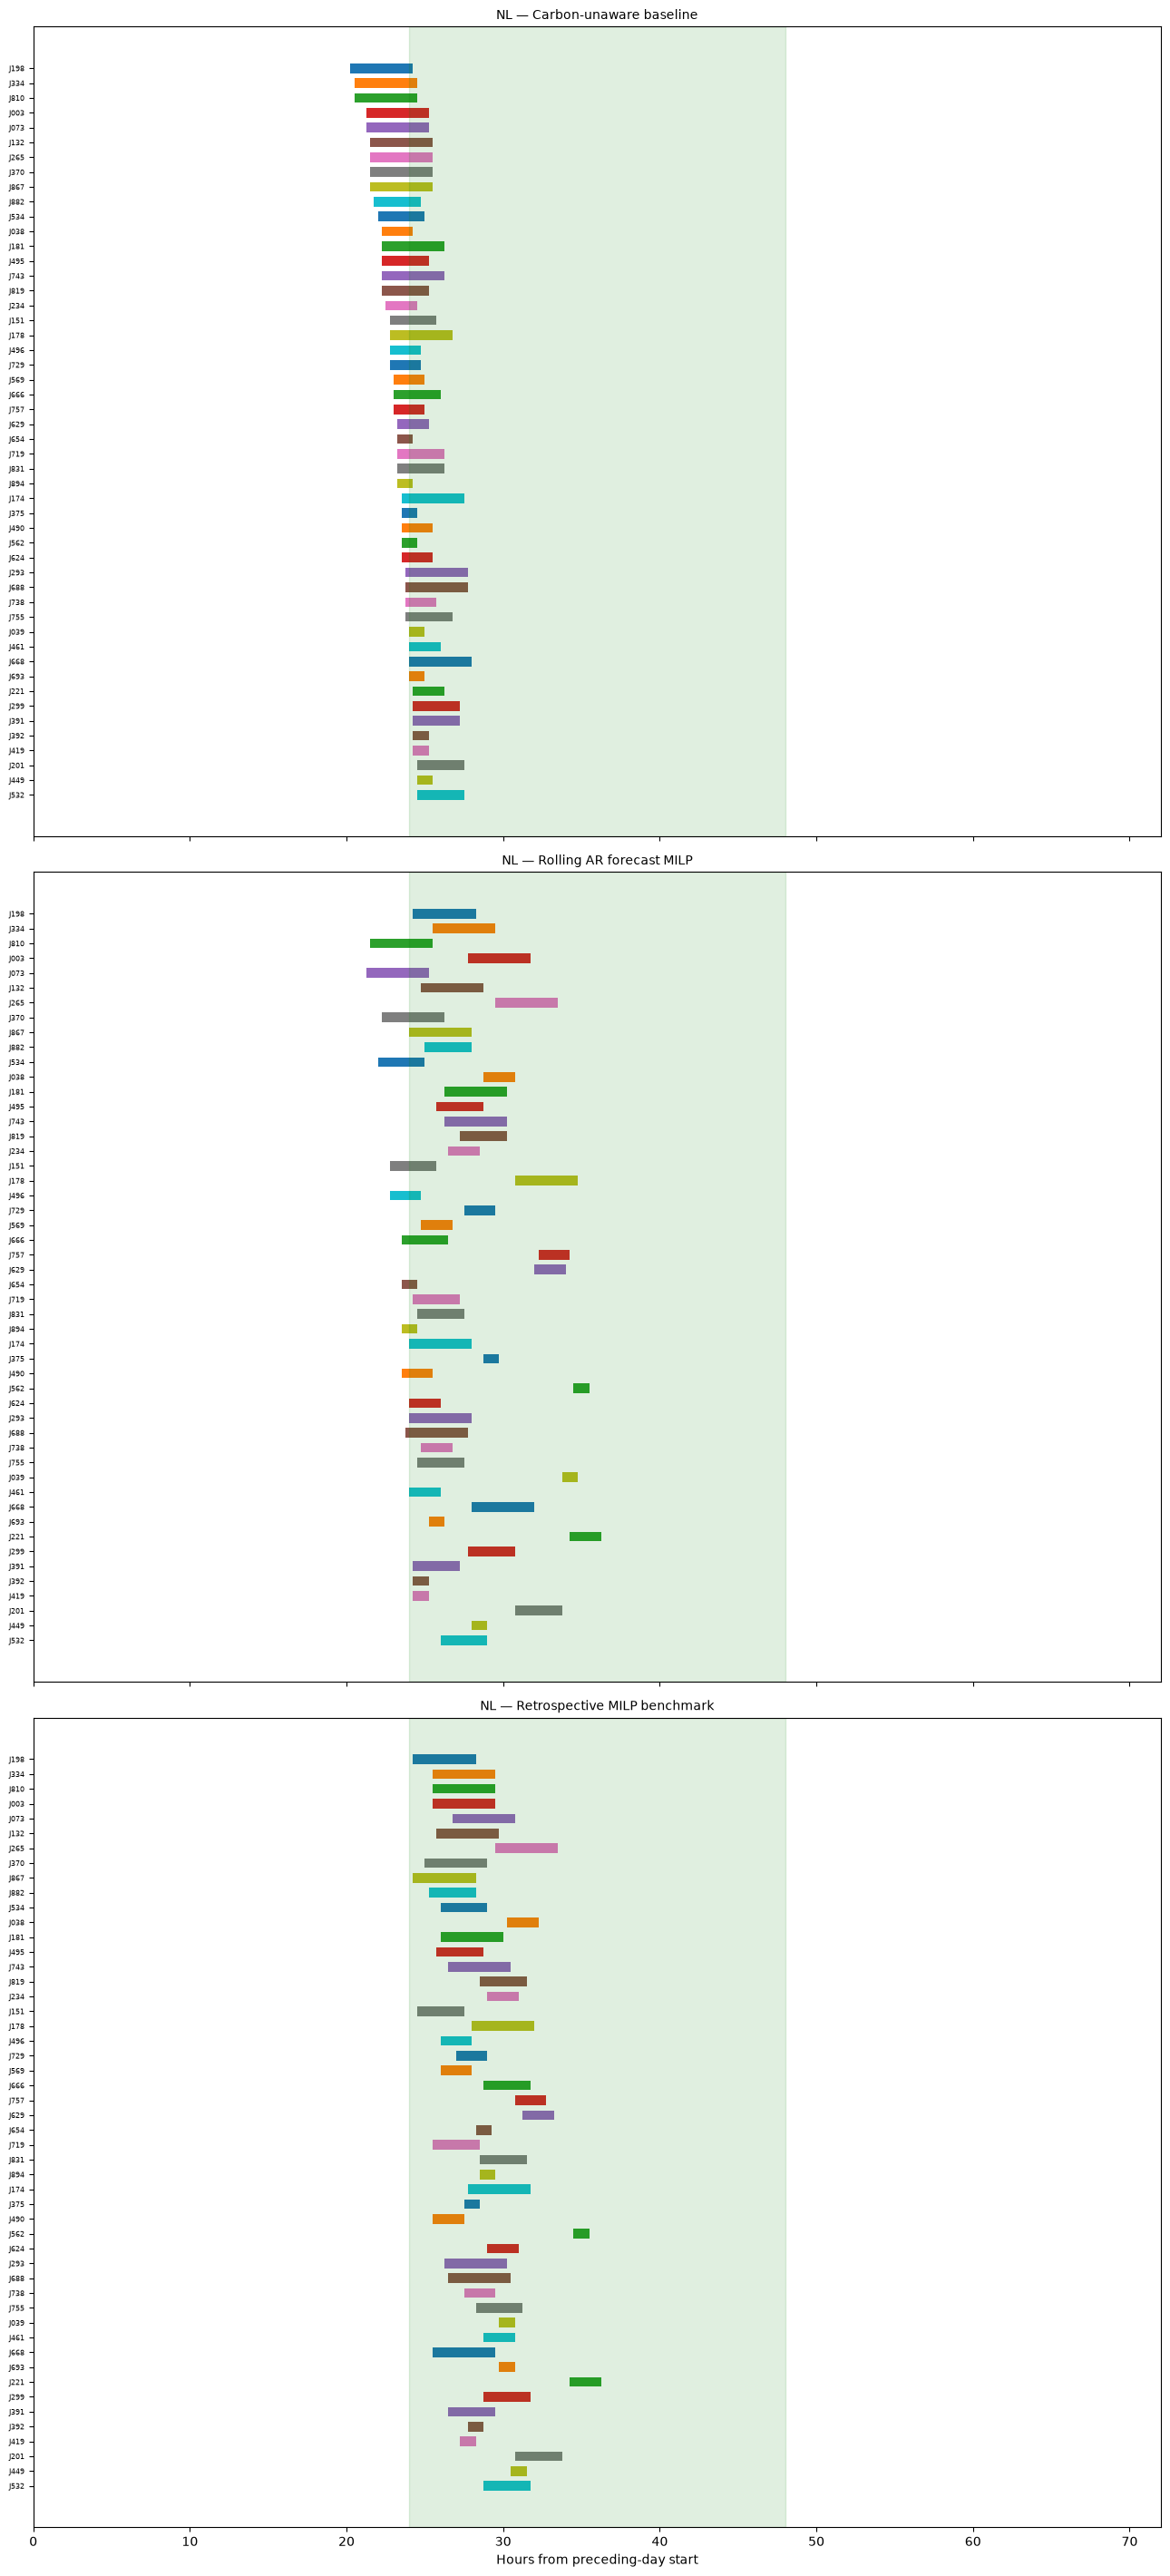

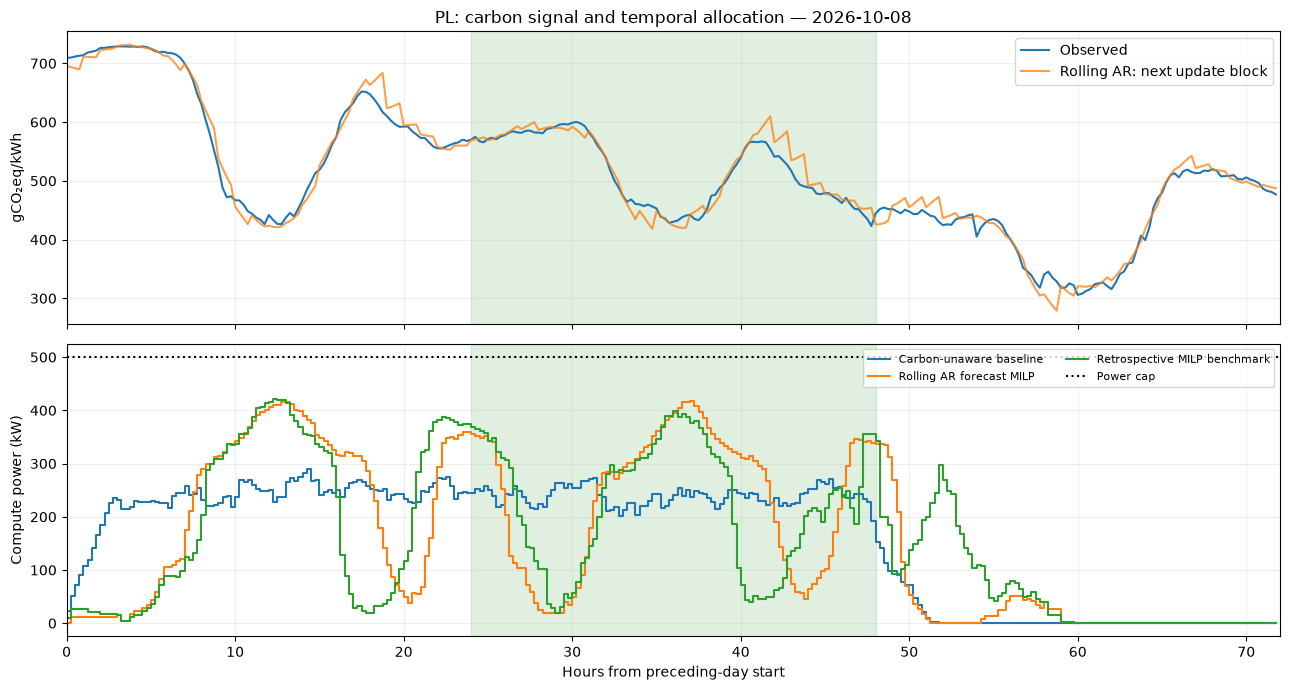

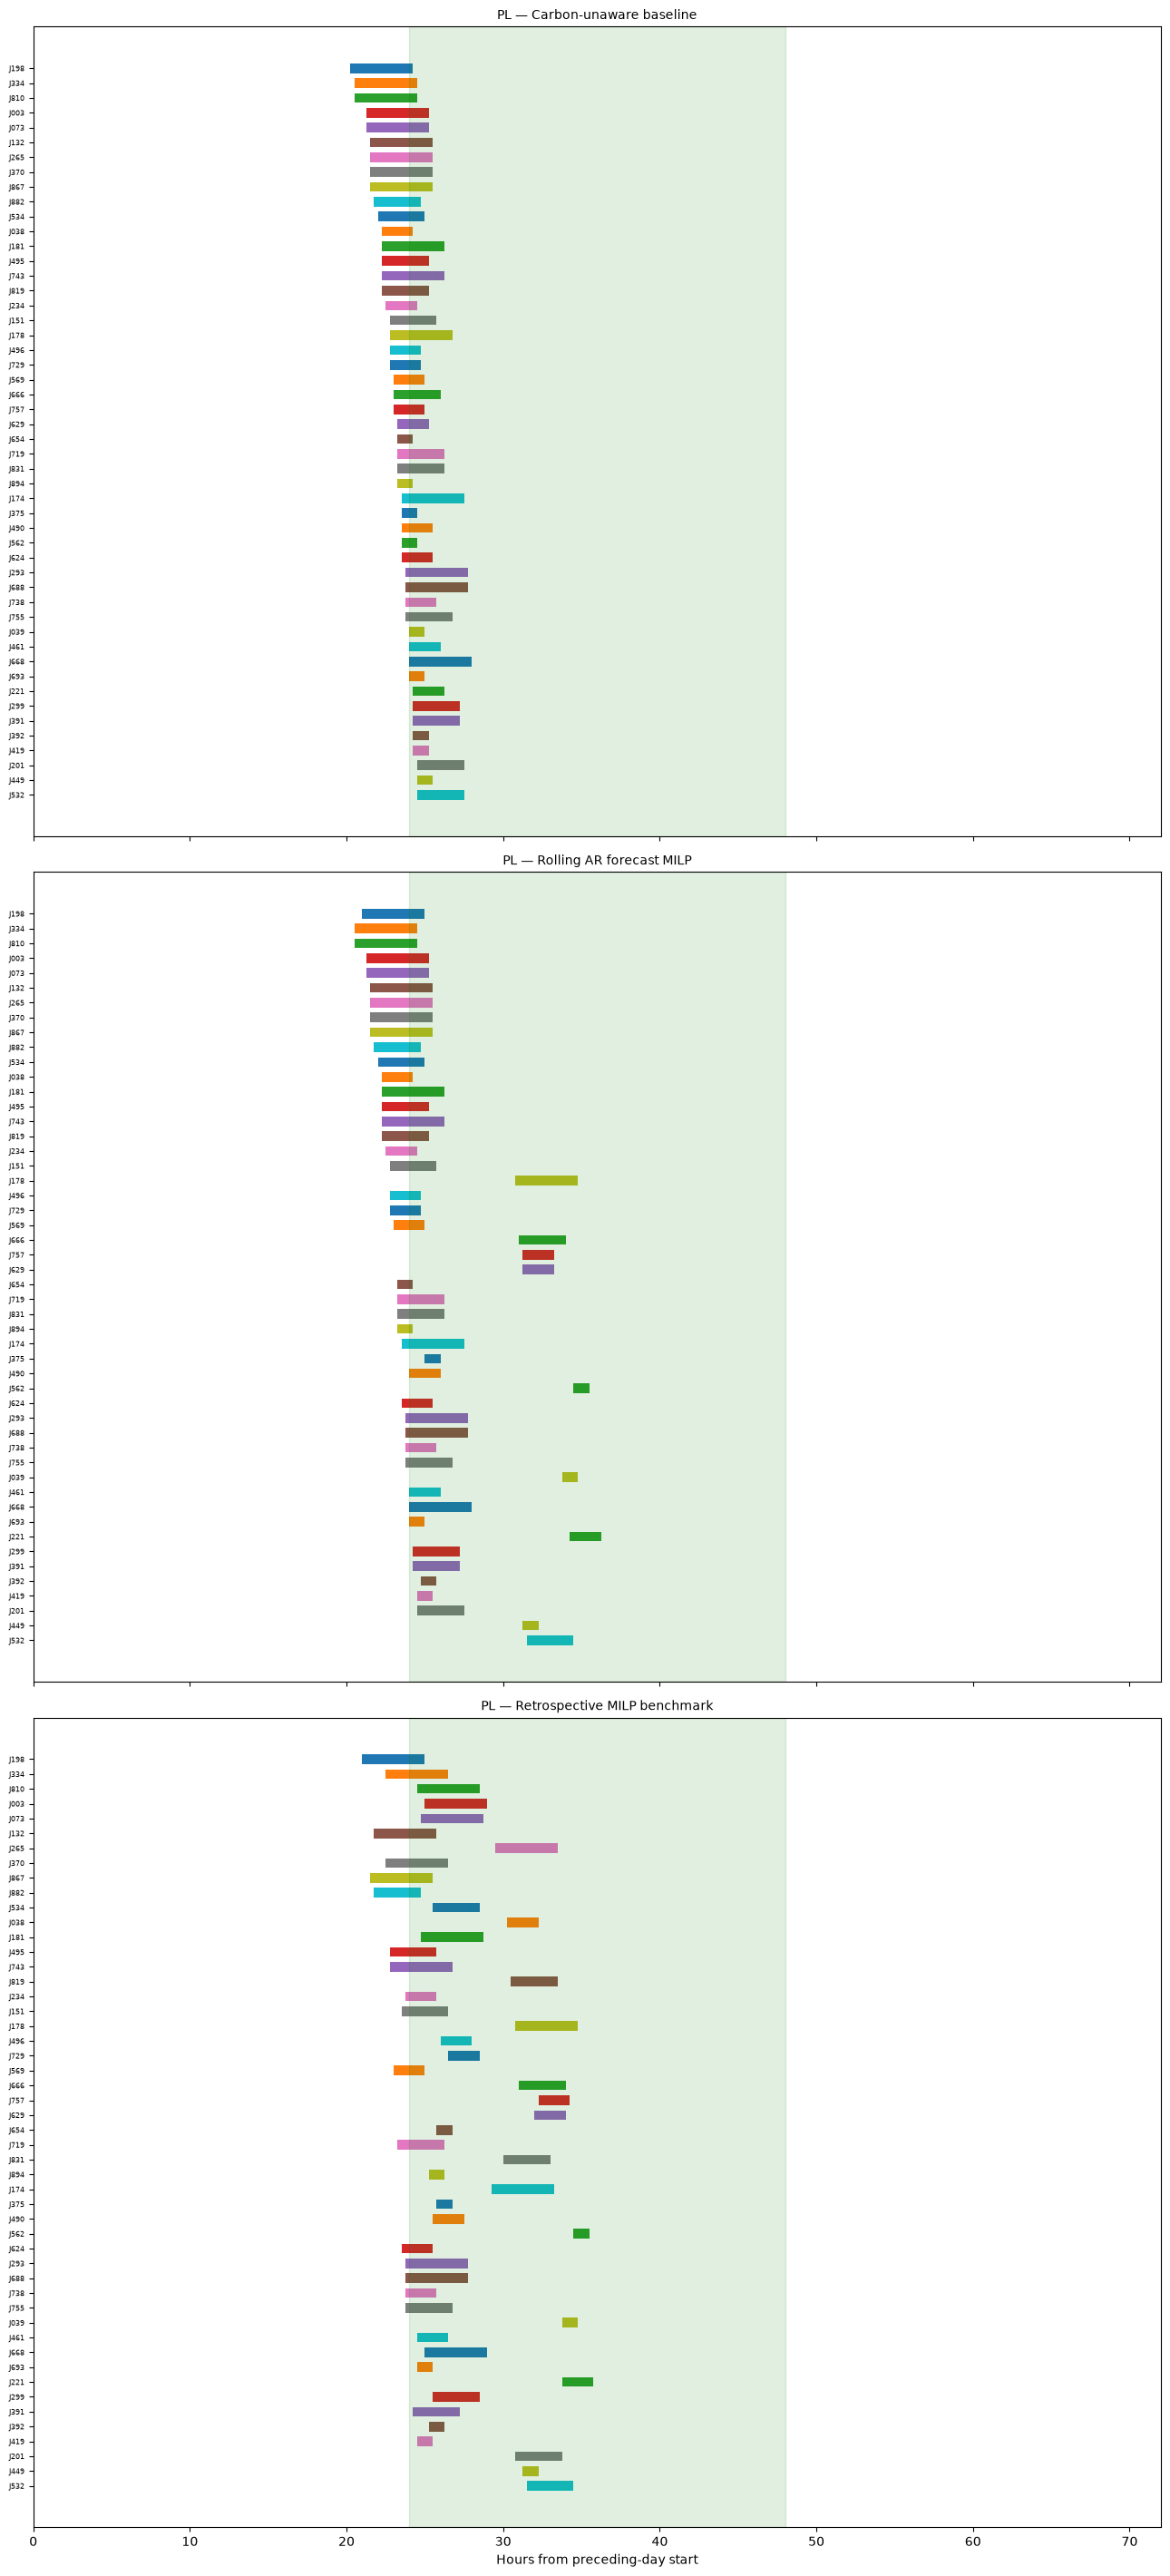

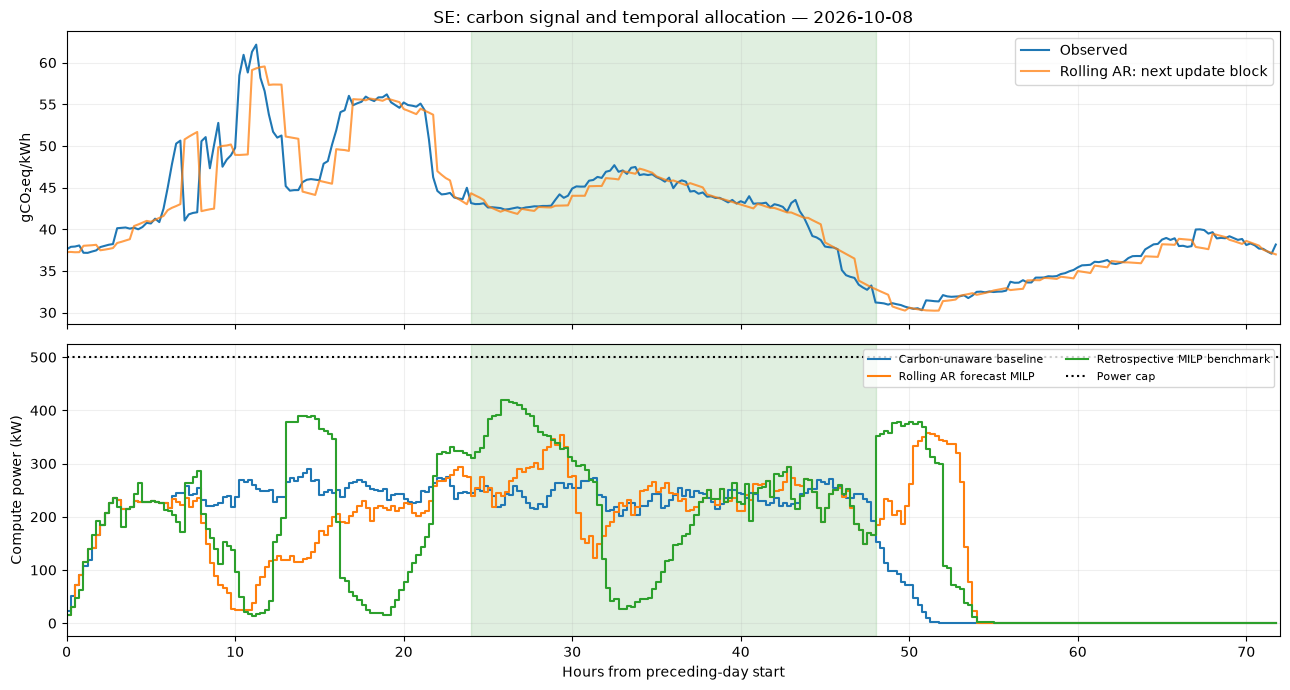

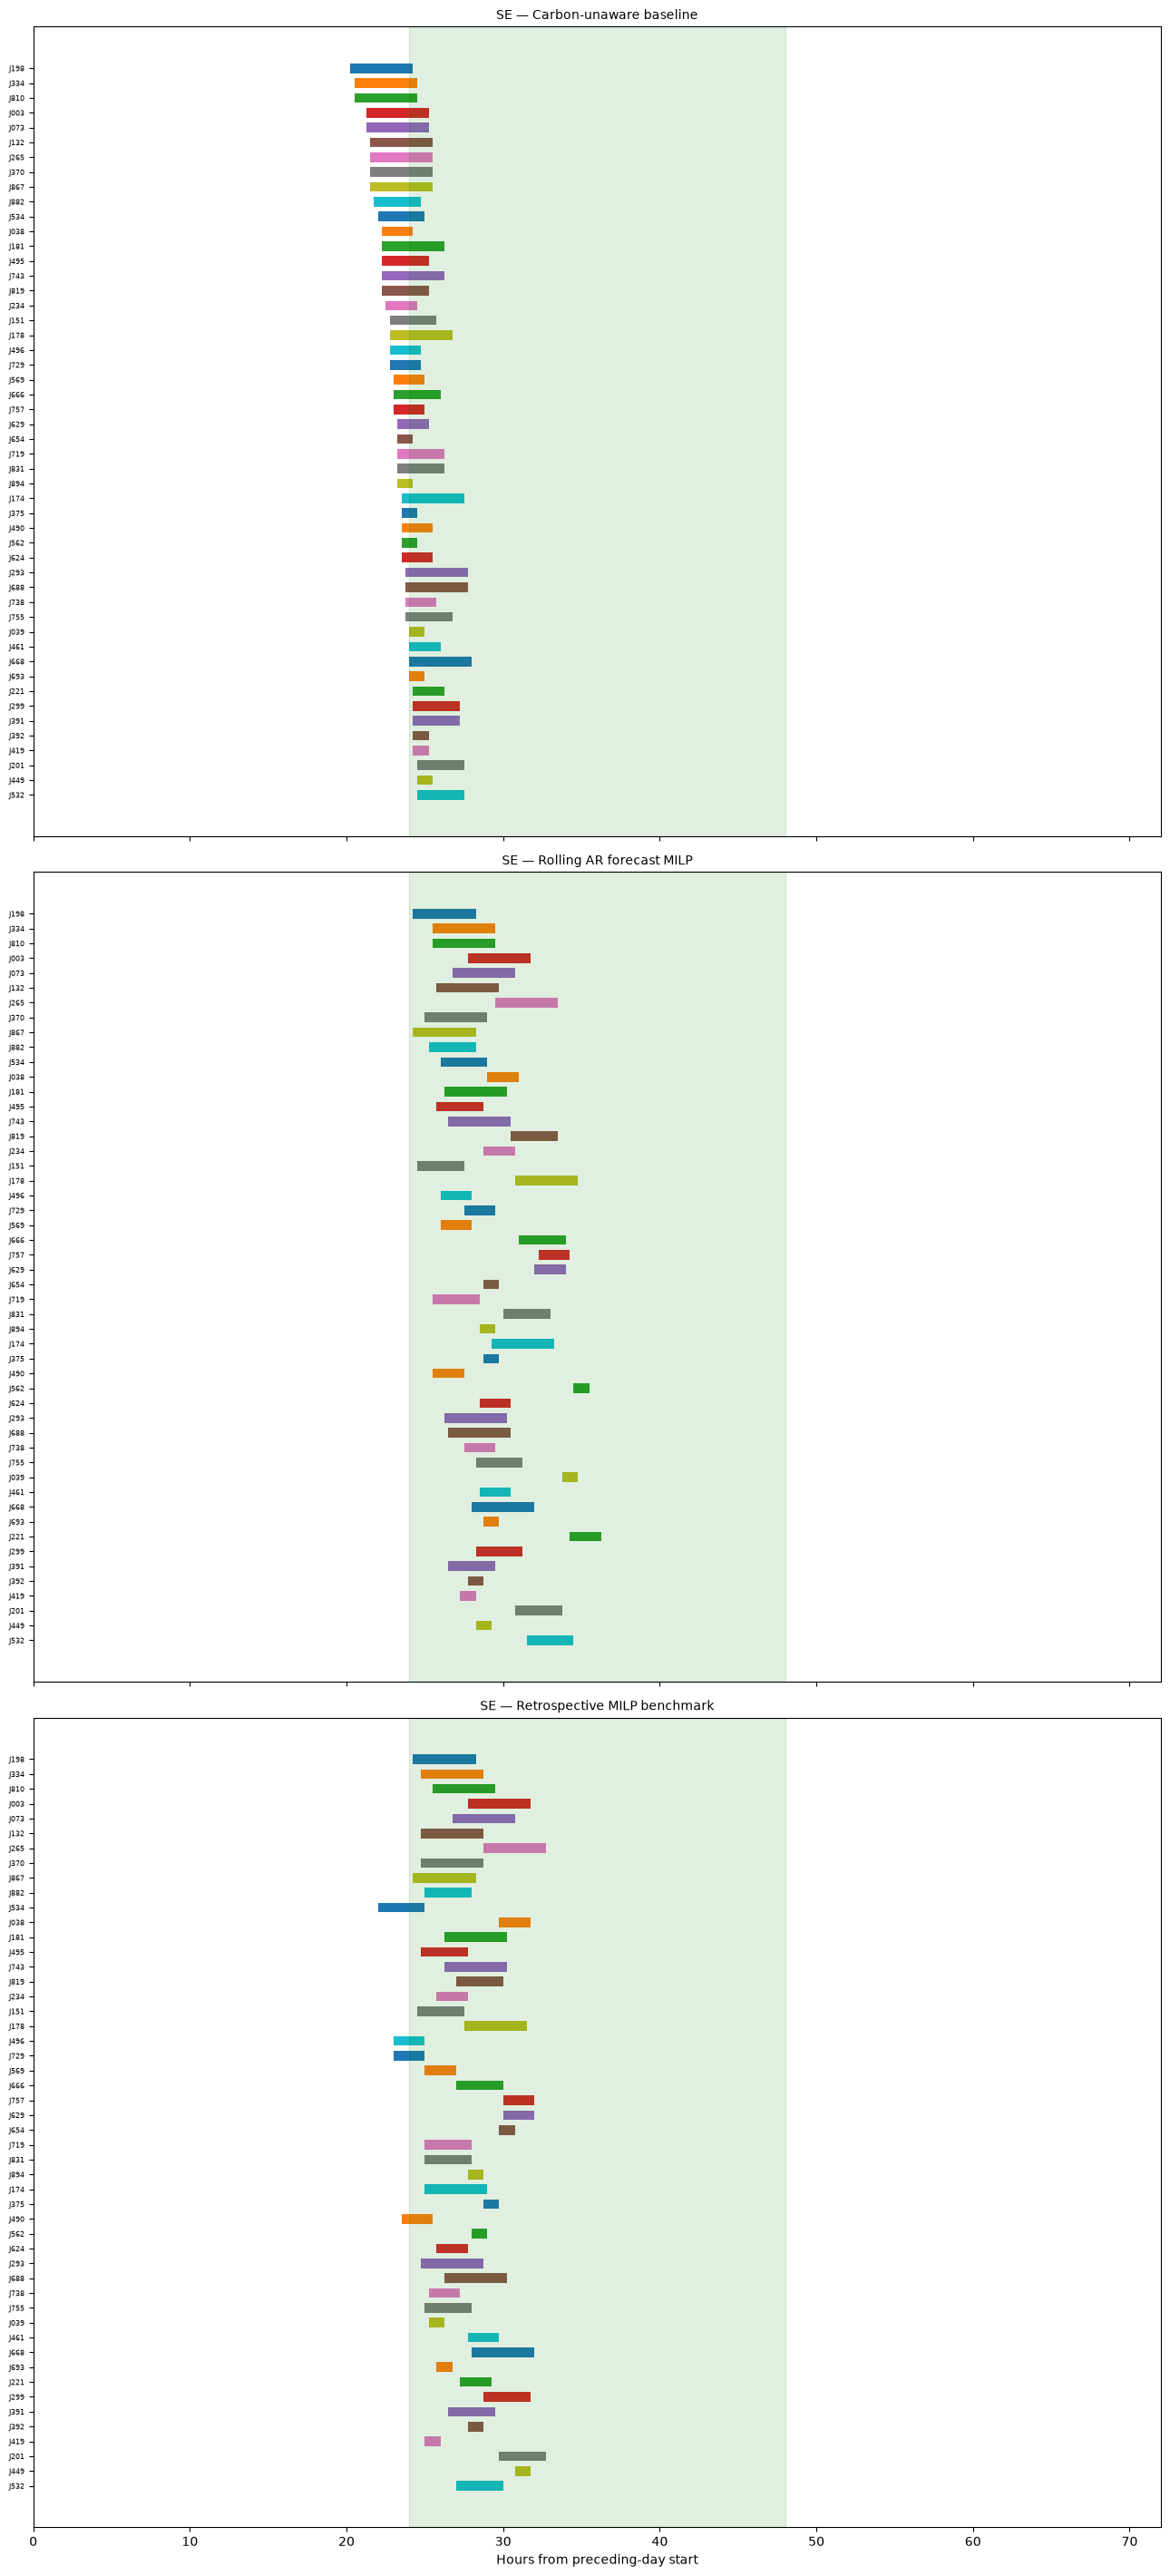

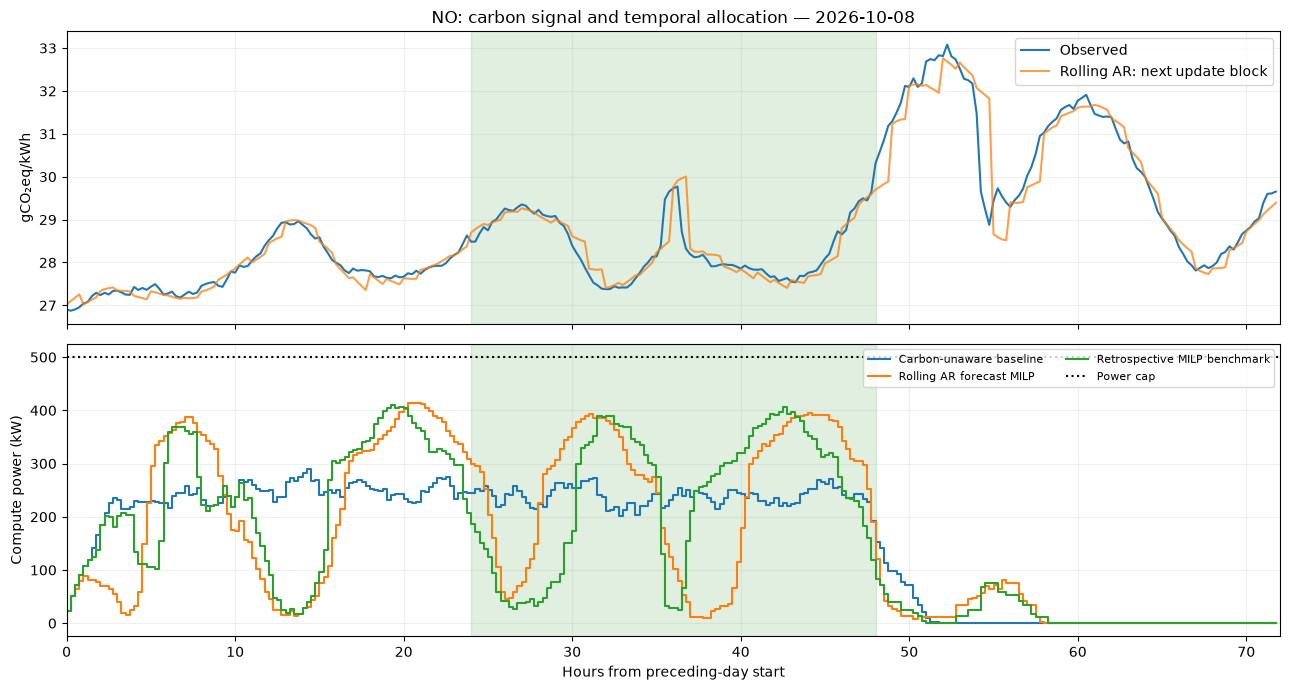

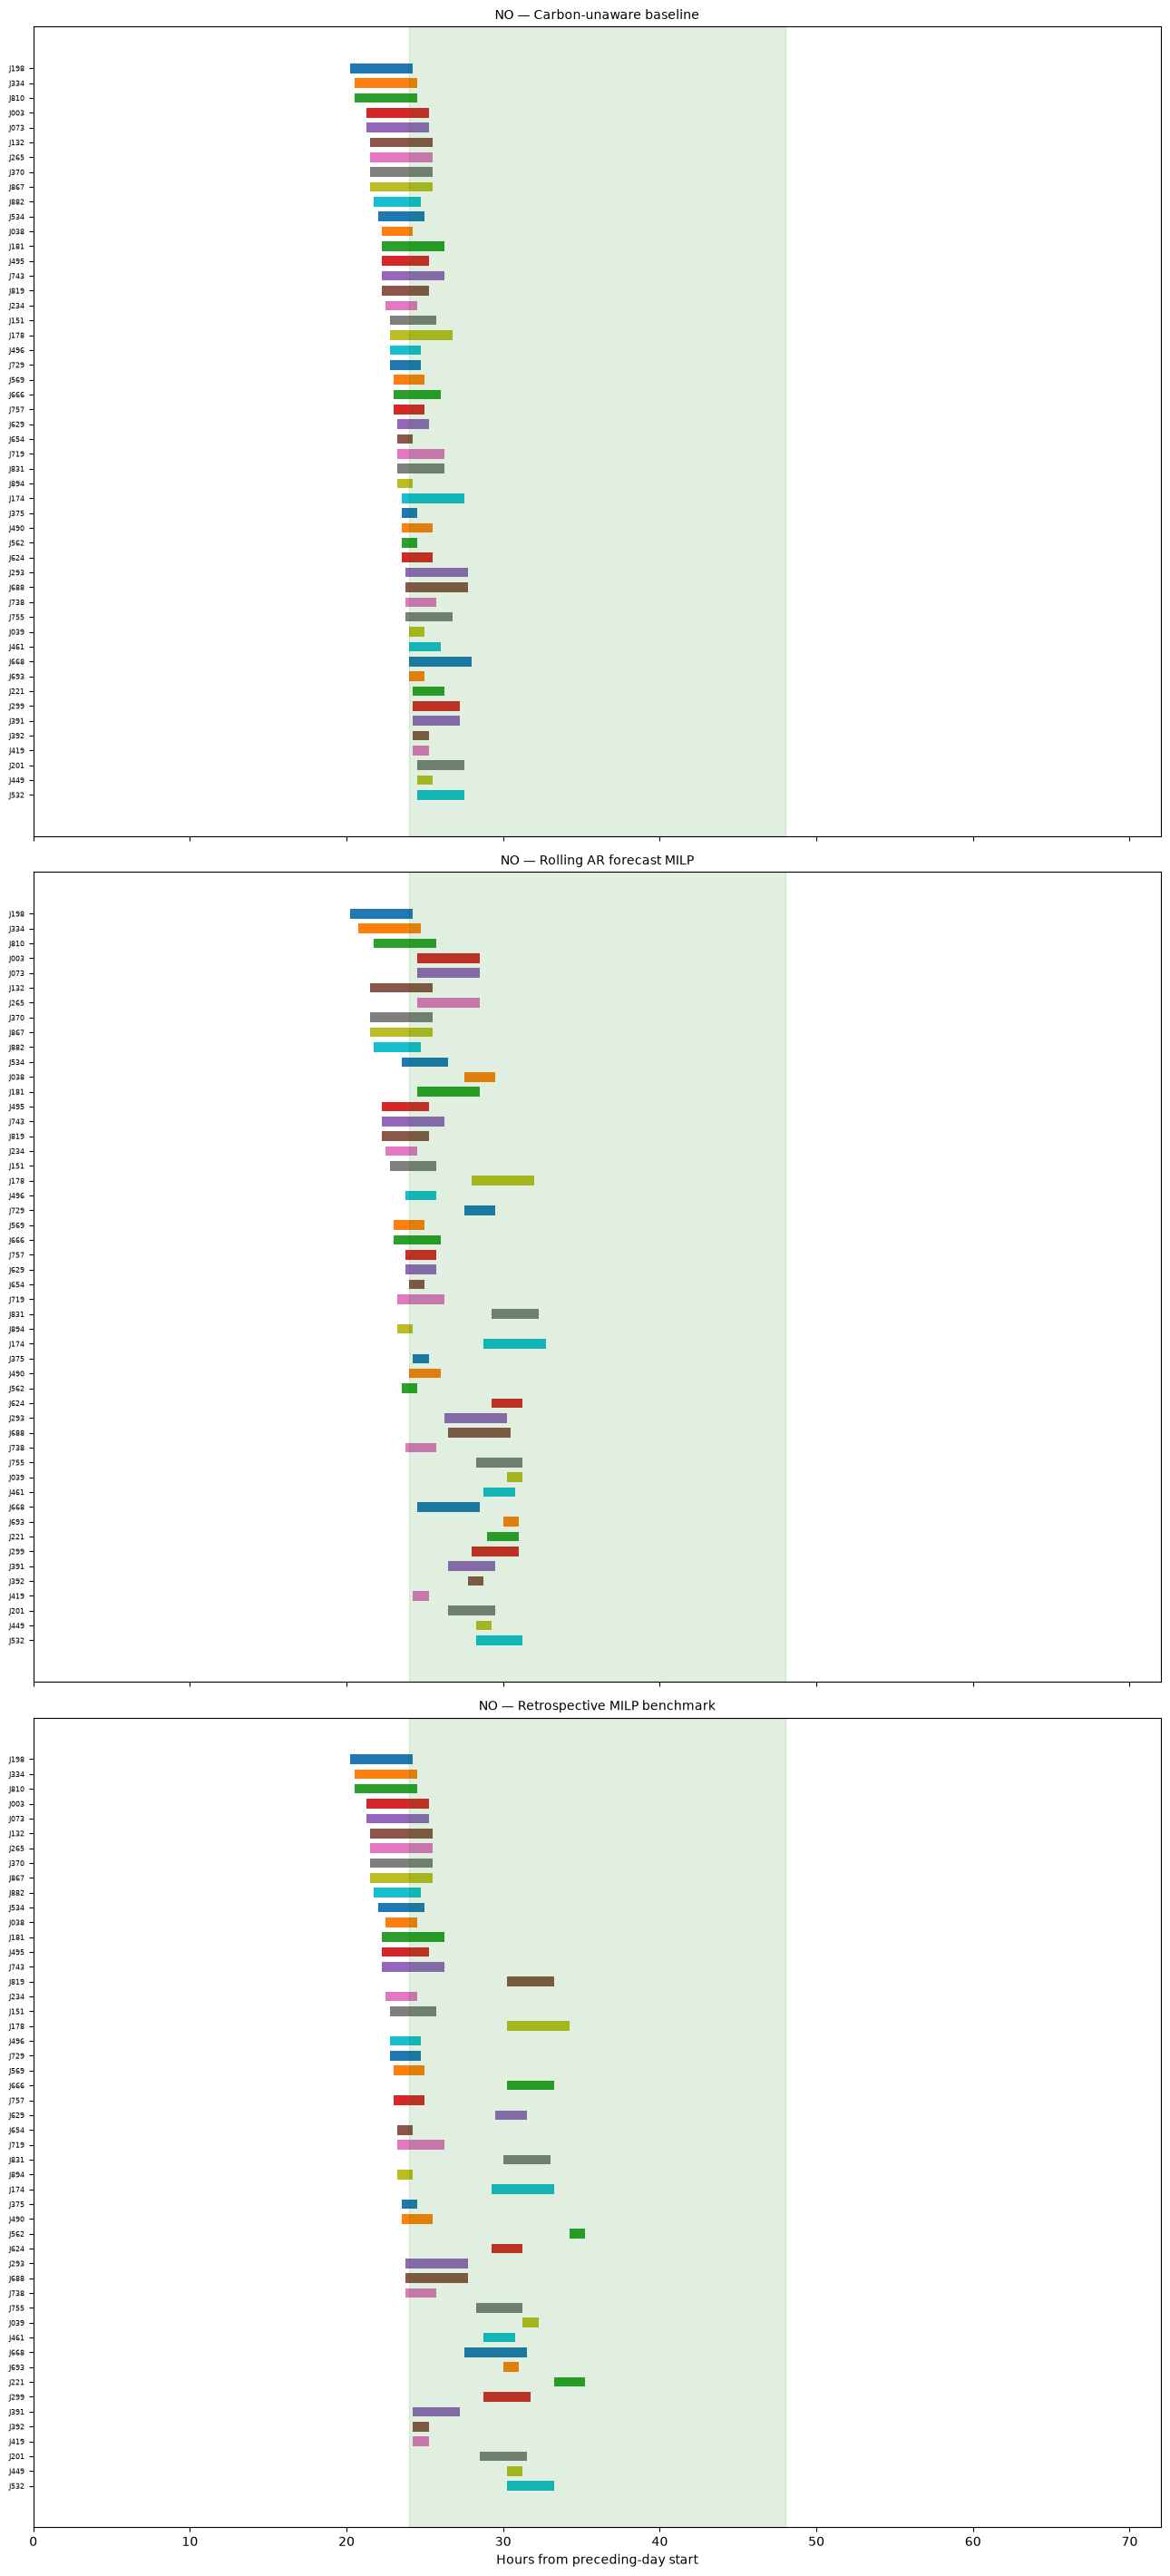

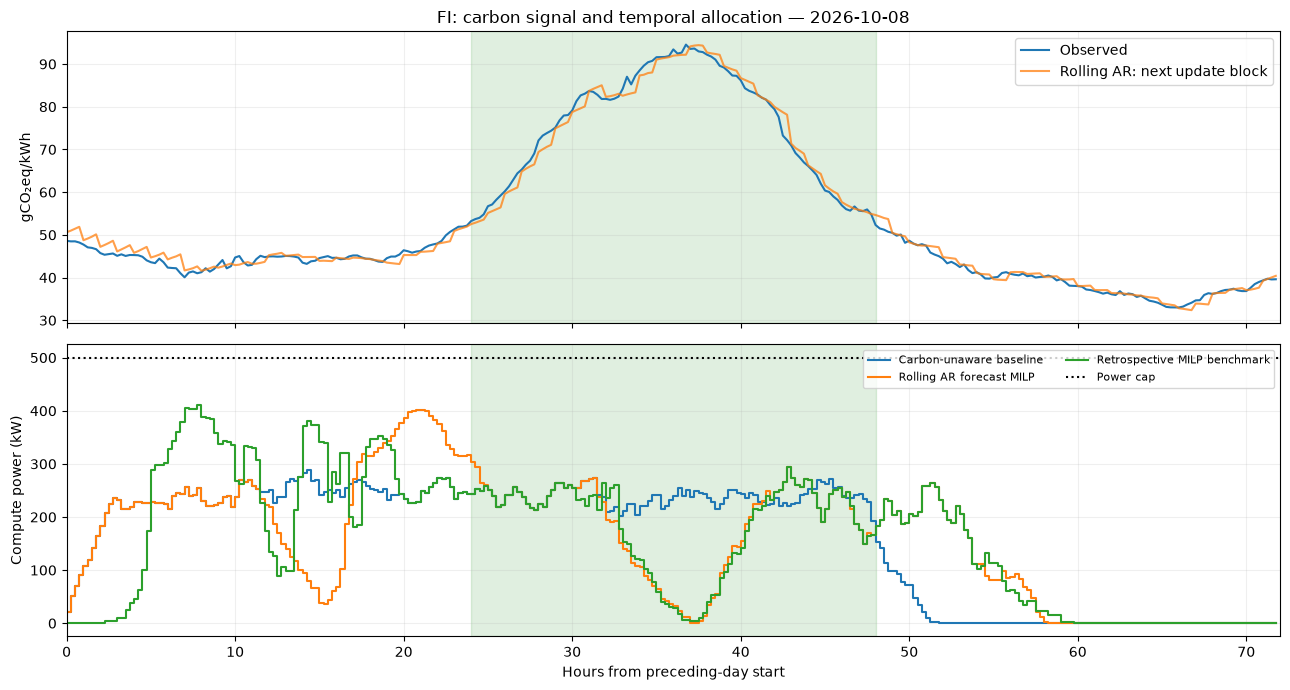

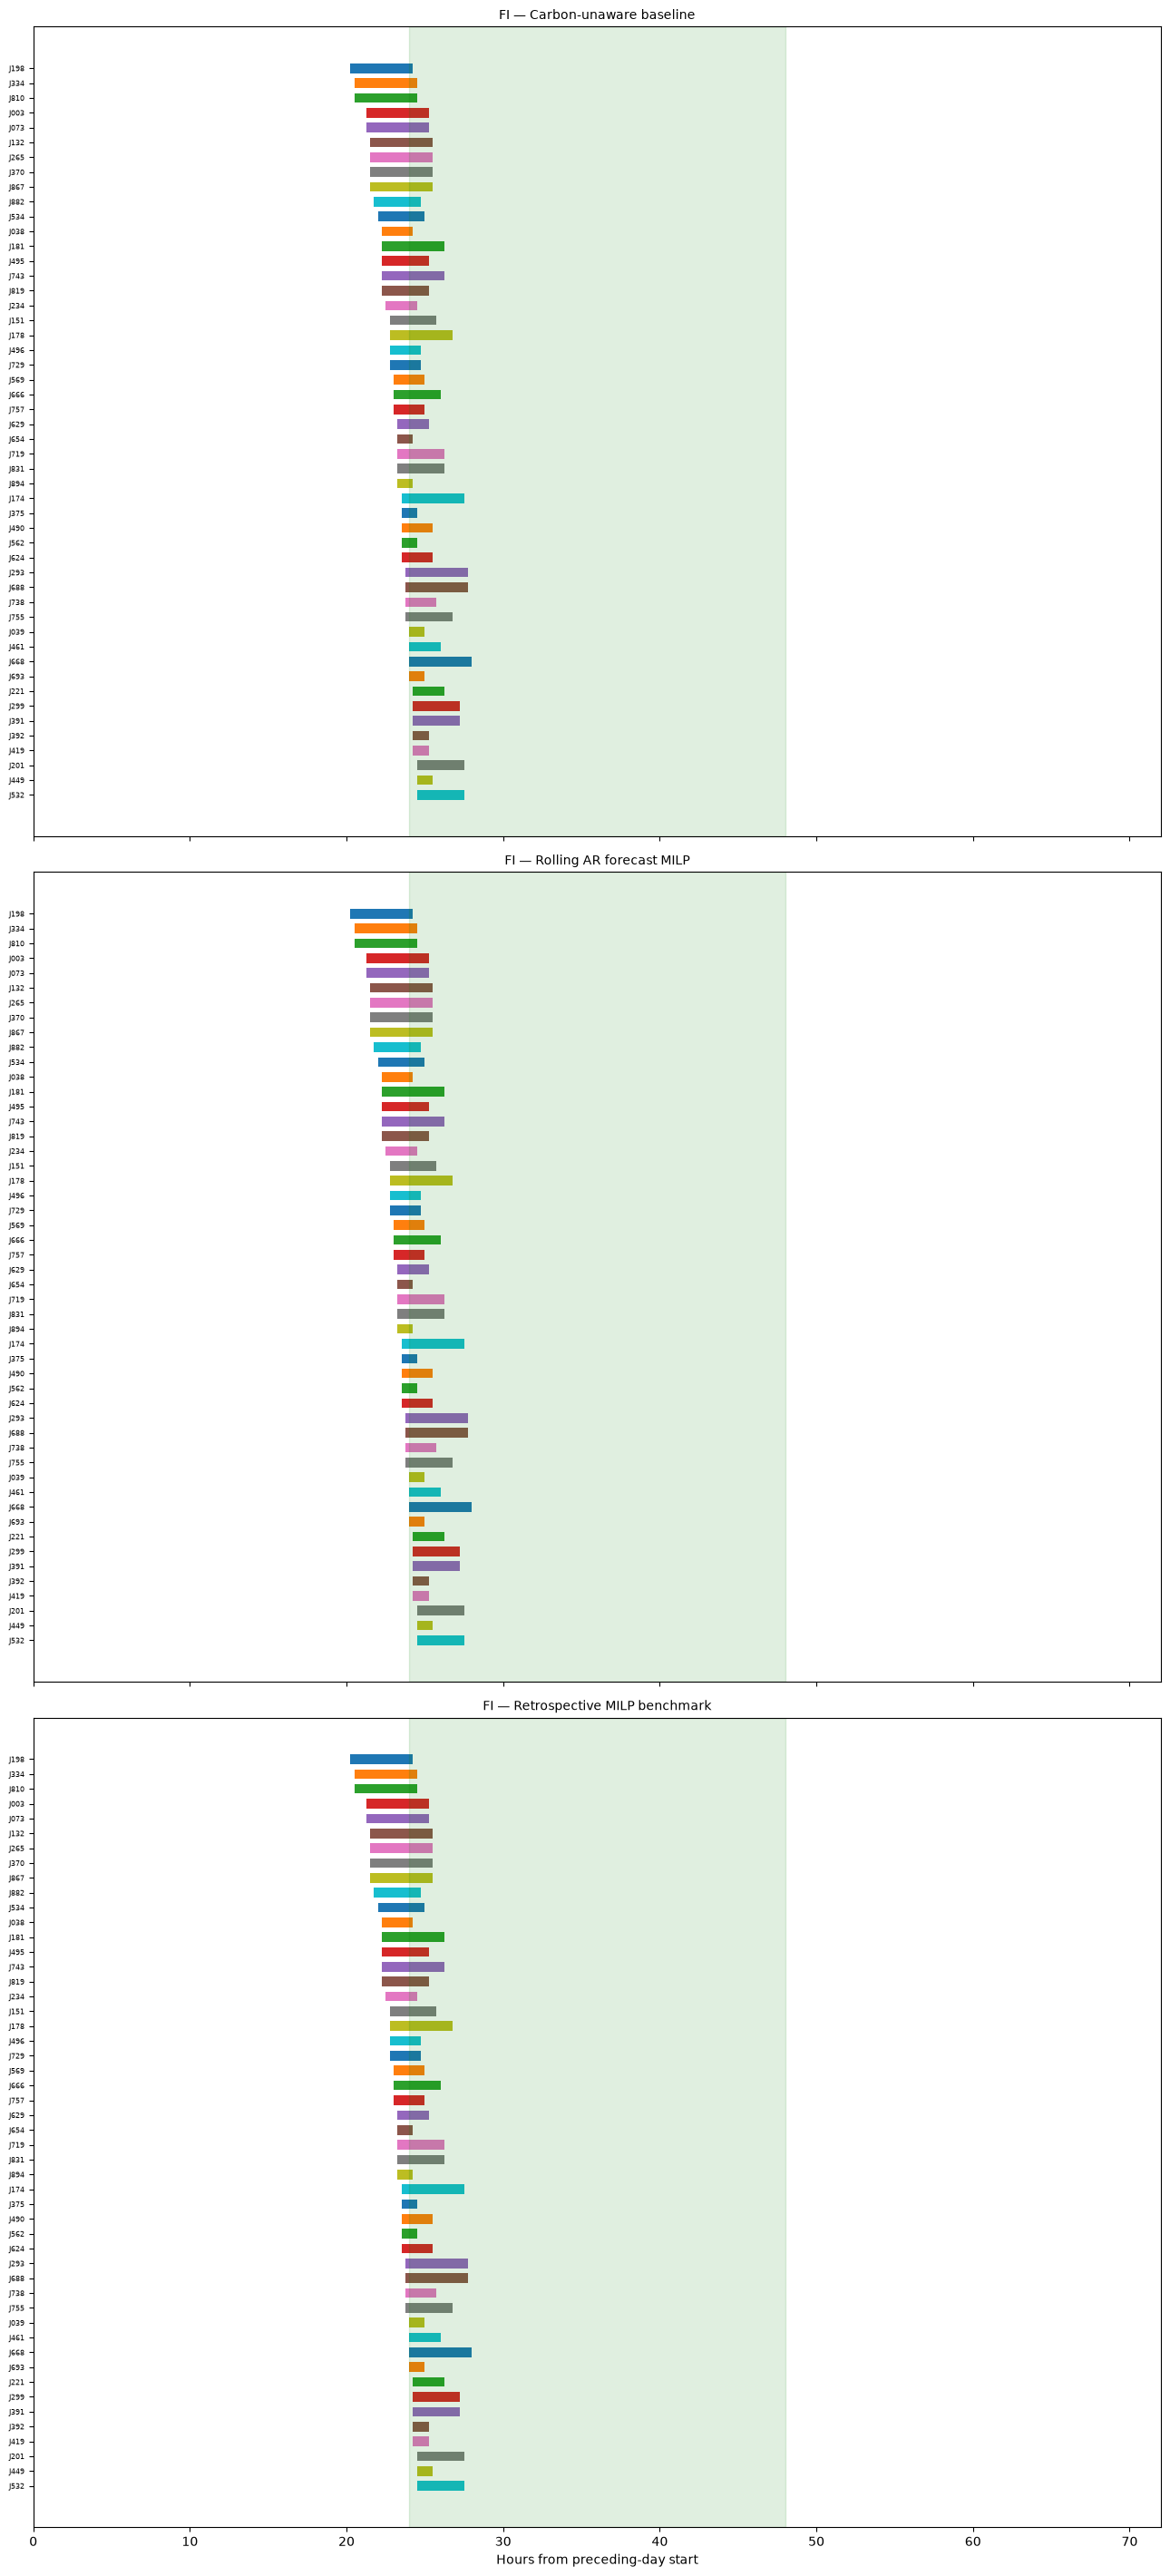

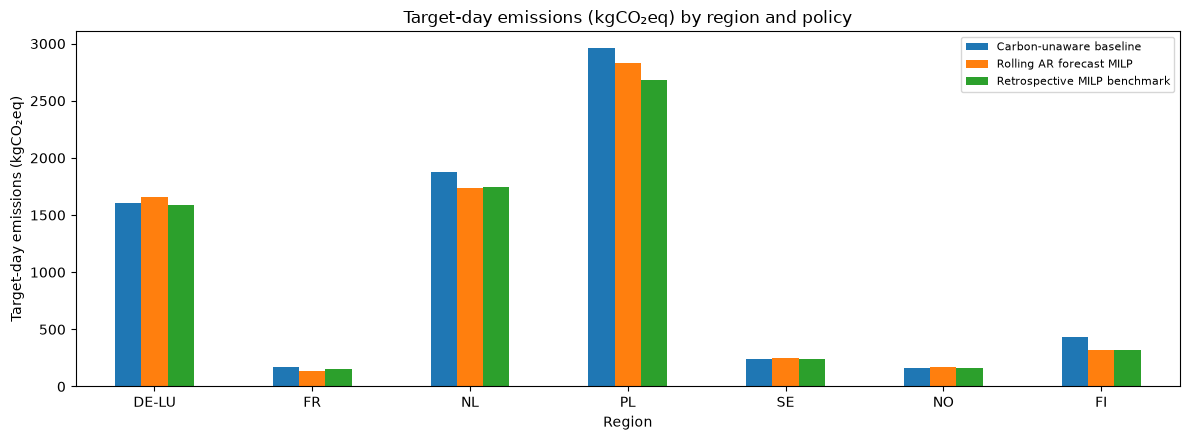

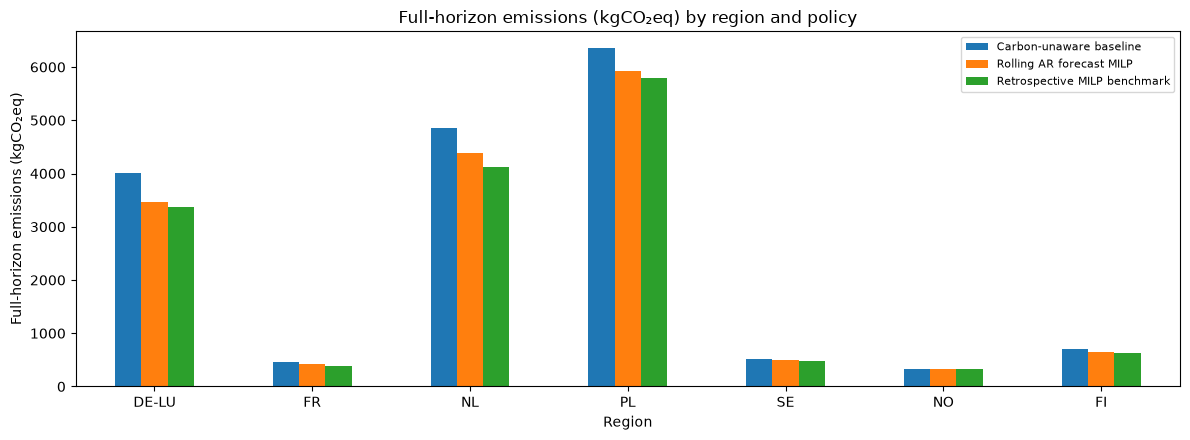

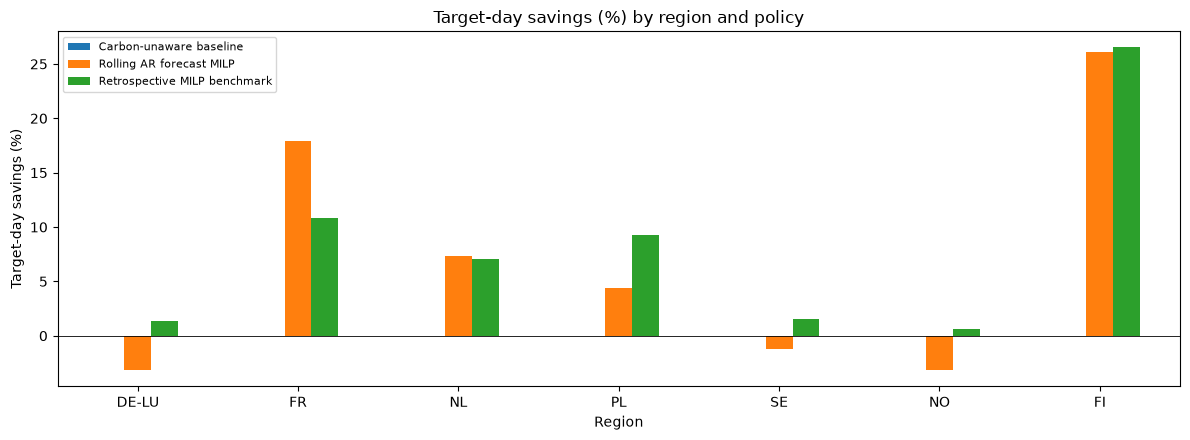

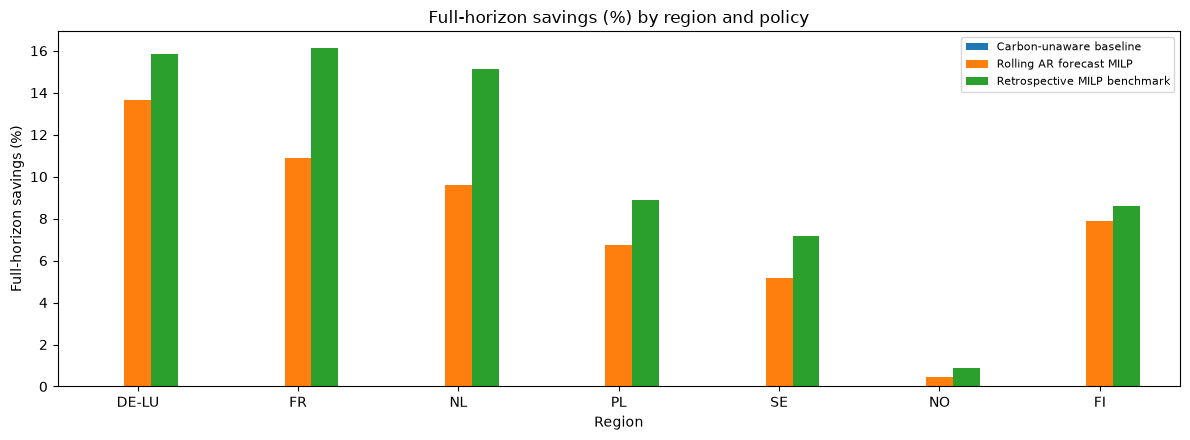

In [13]:
for region,result in demo_results.items():
    hours = np.arange(HORIZON_SLOTS)*SLOT_HOURS
    fig, axes = plt.subplots(2,1,figsize=(13,7),sharex=True)
    axes[0].plot(hours,result["actual_ci"],label="Observed")
    axes[0].plot(hours,result["forecast_ci"],label="Rolling AR: next update block",alpha=.75)
    axes[0].set(ylabel="gCO₂eq/kWh",title=f"{region}: carbon signal and temporal allocation — {DEMO_DATE}")
    axes[0].legend()
    for policy in POLICY_ORDER:
        axes[1].step(hours,result["loads"][policy],where="post",label=policy)
    axes[1].axhline(dc_config.loc[region,"power_capacity_kw"],color="black",ls=":",label="Power cap")
    axes[1].set(xlabel="Hours from preceding-day start",ylabel="Compute power (kW)",xlim=(0,72))
    axes[1].legend(fontsize=8,ncol=2)
    for ax in axes:
        ax.axvspan(24,48,alpha=.12,color="green"); ax.grid(alpha=.2)
    finish_figure(f"06_{region}_ci_and_power")
    baseline_table = result["schedules"][POLICY_BASELINE]
    overlaps = baseline_table[baseline_table["start_slot"].lt(TARGET_END_SLOT) &
                              baseline_table["end_slot"].gt(TARGET_START_SLOT)]
    selected = (overlaps if len(overlaps) else baseline_table).head(GANTT_MAX_JOBS)["task_id"].tolist()
    if selected:
        fig, axes = plt.subplots(3,1,figsize=(13,max(7,len(selected)*.19*3)),sharex=True)
        for ax,policy in zip(axes,POLICY_ORDER):
            schedule = result["schedules"][policy].set_index("task_id")
            for i,task_id in enumerate(selected):
                row = schedule.loc[task_id]
                ax.barh(i,row["duration_hours"],left=row["start_slot"]*SLOT_HOURS,height=.65)
            ax.set_yticks(range(len(selected))); ax.set_yticklabels(selected,fontsize=6)
            ax.invert_yaxis(); ax.set_title(f"{region} — {policy}",fontsize=10)
            ax.axvspan(24,48,alpha=.12,color="green"); ax.set_xlim(0,72)
        axes[-1].set_xlabel("Hours from preceding-day start")
        finish_figure(f"07_{region}_gantt_subset")

for column,label,name in [("emissions_kgCO2eq","Target-day emissions (kgCO₂eq)","08_target_emissions"),
                          ("full_horizon_emissions_kgCO2eq","Full-horizon emissions (kgCO₂eq)","09_full_emissions"),
                          ("target_savings_pct","Target-day savings (%)","10_target_savings"),
                          ("full_horizon_savings_pct","Full-horizon savings (%)","11_full_savings")]:
    values = metrics_table.pivot(index="region",columns="policy",values=column).reindex(regions)[POLICY_ORDER]
    ax = values.plot.bar(figsize=(12,4.5)); ax.set_ylabel(label); ax.set_xlabel("Region")
    ax.set_title(f"{label} by region and policy"); ax.axhline(0,color="black",lw=.6)
    ax.tick_params(axis="x",rotation=0); ax.legend(fontsize=8)
    finish_figure(name)

## 14. Rolling forecast diagnostics

Report the hourly-refitted model's out-of-sample errors for the middle day and by forecast lead. The plotted/target-day MAE and RMSE use only the first hourly block after each issue. The lead-time table scores complete forecast vintages (including longer recursive horizons), grouped by region and lead; overlapping issue/target pairs are intentionally retained. These longer-lead forecasts are the information available for task scheduling. They must not be confused with repeatedly refreshed one-hour forecasts.

The ridge model uses lagged intensity (15 minutes, 30 minutes, one hour, and one day), trailing means, and deterministic daily/weekly calendar terms. Features are standardized using training data only. It refits on a sliding history, then forecasts recursively without reading future actual values. Record the training-window, lag, regularization and update settings with the results. No claim is made that this model outperforms persistence without measured-data validation.

,region,date,forecast_MAE_gCO2eq_kWh,forecast_RMSE_gCO2eq_kWh,forecast_bias_gCO2eq_kWh
0,DE-LU,2026-10-08,9.6439,12.6172,3.8449
1,FR,2026-10-08,2.1222,2.9649,0.9538
2,NL,2026-10-08,11.8978,17.8668,1.2765
3,PL,2026-10-08,12.2142,17.6499,4.4924
4,SE,2026-10-08,0.6465,0.8699,-0.0215
5,NO,2026-10-08,0.1864,0.3198,0.0128
6,FI,2026-10-08,1.4380,1.8442,-0.1946


,region,policy,admission_rate_pct,excluded_jobs,mean_wait_hours,peak_power_kw,peak_concurrent_jobs,capacity_energy_utilization_pct,weighted_CI_gCO2eq_per_kWh,deadline_violations,selected_source,solver_status,solver_success,solver_mip_gap
0,DE-LU,Carbon-unaware baseline,100.0000,0,0.0000,289.0000,50,47.6542,280.9012,0,earliest_feasible,NaN,False,NaN
1,DE-LU,Rolling AR forecast MILP,100.0000,0,3.0250,423.0000,60,50.6562,272.6680,0,milp_incumbent,0.0000,True,0.0000
2,DE-LU,Retrospective MILP benchmark,100.0000,0,4.5275,407.0000,60,47.9125,275.5489,0,milp_incumbent,0.0000,True,0.0057
3,FR,Carbon-unaware baseline,100.0000,0,0.0000,289.0000,50,47.6542,29.8029,0,earliest_feasible,NaN,False,NaN
4,FR,Rolling AR forecast MILP,100.0000,0,2.0761,409.0000,60,43.6896,26.6821,0,milp_incumbent,0.0000,True,0.0053
5,FR,Retrospective MILP benchmark,100.0000,0,3.6608,415.0000,60,48.3875,26.1653,0,milp_incumbent,0.0000,True,0.0015
6,NL,Carbon-unaware baseline,100.0000,0,0.0000,289.0000,50,47.6542,328.0878,0,earliest_feasible,NaN,False,NaN
7,NL,Rolling AR forecast MILP,100.0000,0,3.1858,416.0000,60,48.1063,301.0641,0,milp_incumbent,0.0000,True,0.0000
8,NL,Retrospective MILP benchmark,100.0000,0,3.7631,411.0000,60,48.7292,298.0876,0,milp_incumbent,0.0000,True,0.0011
9,PL,Carbon-unaware baseline,100.0000,0,0.0000,289.0000,50,47.6542,517.6134,0,earliest_feasible,NaN,False,NaN


,region,date,workload_seed,capacity_scale,experiment,policy,n_jobs,candidate_variables,time_limit_seconds,status,solver_success,solver_message,solver_incumbent_objective_kg,solver_mip_gap,dual_bound_kg,selected_source,used_reference,no_solver_incumbent,selected_objective_kg,selected_gap_to_bound
0,DE-LU,2026-10-08,42,1.0000,demo,Rolling AR forecast MILP,900,21643,60,0,True,Optimization terminated successfully. (HiGHS S...,"3,645.8563",0.0000,"3,645.8563",milp_incumbent,False,False,"3,645.8563",0.0000
1,DE-LU,2026-10-08,42,1.0000,demo,Retrospective MILP benchmark,900,21643,60,0,True,Optimization terminated successfully. (HiGHS S...,"3,370.1501",0.0057,"3,350.8831",milp_incumbent,False,False,"3,370.1501",0.0057
2,FR,2026-10-08,42,1.0000,demo,Rolling AR forecast MILP,900,21643,60,0,True,Optimization terminated successfully. (HiGHS S...,459.3810,0.0053,456.9572,milp_incumbent,False,False,459.3810,0.0053
3,FR,2026-10-08,42,1.0000,demo,Retrospective MILP benchmark,900,21643,60,0,True,Optimization terminated successfully. (HiGHS S...,388.9675,0.0015,388.3895,milp_incumbent,False,False,388.9675,0.0015
4,NL,2026-10-08,42,1.0000,demo,Rolling AR forecast MILP,900,21643,60,0,True,Optimization terminated successfully. (HiGHS S...,"4,849.5209",0.0000,"4,849.5201",milp_incumbent,False,False,"4,849.5209",0.0000
5,NL,2026-10-08,42,1.0000,demo,Retrospective MILP benchmark,900,21643,60,0,True,Optimization terminated successfully. (HiGHS S...,"4,125.2886",0.0011,"4,120.9214",milp_incumbent,False,False,"4,125.2886",0.0011
6,PL,2026-10-08,42,1.0000,demo,Rolling AR forecast MILP,900,21643,60,0,True,Optimization terminated successfully. (HiGHS S...,"6,035.8900",0.0000,"6,035.8890",milp_incumbent,False,False,"6,035.8900",0.0000
7,PL,2026-10-08,42,1.0000,demo,Retrospective MILP benchmark,900,21643,60,0,True,Optimization terminated successfully. (HiGHS S...,"5,786.2681",0.0001,"5,785.8186",milp_incumbent,False,False,"5,786.2681",0.0001
8,SE,2026-10-08,42,1.0000,demo,Rolling AR forecast MILP,900,21643,60,0,True,Optimization terminated successfully. (HiGHS S...,488.2725,0.0000,488.2725,milp_incumbent,False,False,488.2725,0.0000
9,SE,2026-10-08,42,1.0000,demo,Retrospective MILP benchmark,900,21643,60,0,True,Optimization terminated successfully. (HiGHS S...,484.9650,0.0001,484.9077,milp_incumbent,False,False,484.9650,0.0001


,region,lead_slots,lead_hours,n_forecasts,MAE_gCO2eq_kWh,bias_gCO2eq_kWh,RMSE_gCO2eq_kWh
0,DE-LU,1,0.2500,72,4.8328,1.5506,6.1343
1,DE-LU,2,0.5000,72,7.7092,3.1874,10.0813
2,DE-LU,3,0.7500,72,11.5351,4.6793,15.0583
3,DE-LU,4,1.0000,72,15.6412,6.1050,20.2280
4,DE-LU,5,1.2500,71,19.5460,7.9935,25.1939
...,...,...,...,...,...,...,...
359,SE,48,12.0000,61,5.2669,-3.0307,6.2462
360,SE,49,12.2500,60,5.1533,-2.8709,6.1376
361,SE,50,12.5000,60,5.1956,-2.9479,6.1797
362,SE,51,12.7500,60,5.1737,-2.9930,6.1760


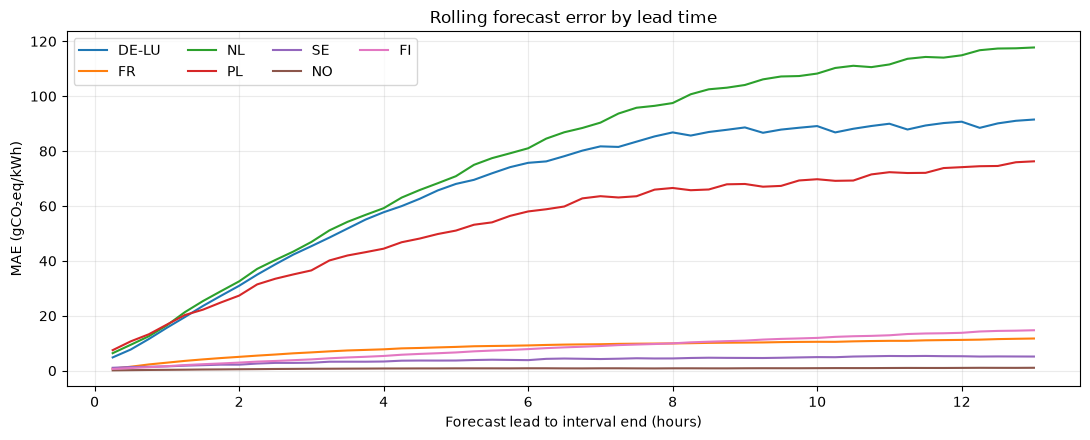

In [14]:
forecast_rows = []
# forecast_ci is the sequence of first update-blocks; longer-lead errors are scored separately.
for region,result in demo_results.items():
    actual = result["actual_ci"][TARGET_START_SLOT:TARGET_END_SLOT]
    error = result["forecast_ci"][TARGET_START_SLOT:TARGET_END_SLOT]-actual
    actual_mean = np.mean(actual)
    mae = np.abs(error).mean()
    rmse = np.sqrt(np.mean(error**2))
    actual_scale = abs(actual_mean)
    forecast_rows.append({"region":region,"date":DEMO_DATE,"forecast_MAE_gCO2eq_kWh":mae,
                          "forecast_MAE_pct":100*mae/actual_scale if actual_scale else np.nan,
                          "forecast_RMSE_gCO2eq_kWh":rmse,
                          "forecast_RMSE_pct":100*rmse/actual_scale if actual_scale else np.nan,
                          "forecast_bias_gCO2eq_kWh":error.mean()})
forecast_diagnostics = pd.DataFrame(forecast_rows)
display(forecast_diagnostics)
display(metrics_table[["region","policy","admission_rate_pct","excluded_jobs","mean_wait_hours",
    "peak_power_kw","peak_concurrent_jobs","capacity_energy_utilization_pct","weighted_CI_gCO2eq_per_kWh",
    "deadline_violations","selected_source","solver_status","solver_success","solver_mip_gap"]])
display(pd.DataFrame(MILP_SOLVE_LOG))

forecast_demo_details = pd.concat([r["forecast_bundle"]["details"] for r in demo_results.values()],ignore_index=True)
forecast_demo_details["absolute_error"] = forecast_demo_details["error_gCO2eq_kWh"].abs()
forecast_demo_details["squared_error"] = forecast_demo_details["error_gCO2eq_kWh"]**2
forecast_lead_metrics = forecast_demo_details.groupby(["region","lead_slots","lead_hours"]).agg(
    n_forecasts=("error_gCO2eq_kWh","size"),MAE_gCO2eq_kWh=("absolute_error","mean"),
    MSE_gCO2eq_kWh=("squared_error","mean"),bias_gCO2eq_kWh=("error_gCO2eq_kWh","mean")).reset_index()
forecast_lead_metrics["RMSE_gCO2eq_kWh"] = np.sqrt(forecast_lead_metrics.pop("MSE_gCO2eq_kWh"))
display(forecast_lead_metrics)
fit_log = pd.DataFrame(FORECAST_FIT_LOG)
assert (pd.to_datetime(fit_log["train_last_target"],utc=True) < pd.to_datetime(fit_log["issue_time_utc"],utc=True)).all()
fig, ax = plt.subplots(figsize=(11,4.5))
for region in regions:
    subset = forecast_lead_metrics[forecast_lead_metrics["region"]==region]
    ax.plot(subset["lead_hours"],subset["MAE_gCO2eq_kWh"],label=region)
ax.set(xlabel="Forecast lead to interval end (hours)",ylabel="MAE (gCO₂eq/kWh)",title="Rolling forecast error by lead time")
ax.legend(ncol=4); ax.grid(alpha=.25)
finish_figure("14_rolling_forecast_error_by_lead")

## 15. Sensitivity to regional resource capacity

Scale both power and concurrency caps relative to each region's configured values, keeping the generated task table unchanged. Each scenario has its own baseline-accepted common task subset. Report exclusions and admitted work alongside savings; comparisons across capacity levels may involve different accepted sets. Multipliers replace the old hard-coded 18/22/26 kW values, which were inconsistent with a 500 kW main experiment.

Capacity scenario: DE-LU, multiplier=0.6
Capacity scenario: DE-LU, multiplier=0.8
Capacity scenario: DE-LU, multiplier=1
Capacity scenario: DE-LU, multiplier=1.2
Capacity scenario: DE-LU, multiplier=1.4
Capacity scenario: FR, multiplier=0.6
Capacity scenario: FR, multiplier=0.8
Capacity scenario: FR, multiplier=1
Capacity scenario: FR, multiplier=1.2
Capacity scenario: FR, multiplier=1.4
Capacity scenario: NL, multiplier=0.6
Capacity scenario: NL, multiplier=0.8
Capacity scenario: NL, multiplier=1
Capacity scenario: NL, multiplier=1.2
Capacity scenario: NL, multiplier=1.4
Capacity scenario: PL, multiplier=0.6
Capacity scenario: PL, multiplier=0.8
Capacity scenario: PL, multiplier=1
Capacity scenario: PL, multiplier=1.2
Capacity scenario: PL, multiplier=1.4
Capacity scenario: SE, multiplier=0.6
Capacity scenario: SE, multiplier=0.8
Capacity scenario: SE, multiplier=1
Capacity scenario: SE, multiplier=1.2
Capacity scenario: SE, multiplier=1.4
Capacity scenario: NO, multiplier=0.6
Capacit

,region,capacity_scale,policy,scheduled_jobs,excluded_jobs,admission_rate_pct,target_savings_pct,full_horizon_savings_pct,selected_source
0,DE-LU,0.6000,Carbon-unaware baseline,830,70,92.2222,0.0000,0.0000,earliest_feasible
1,DE-LU,0.6000,Rolling AR forecast MILP,830,70,92.2222,0.5733,5.0669,milp_incumbent
2,DE-LU,0.6000,Retrospective MILP benchmark,830,70,92.2222,1.2913,8.1892,milp_incumbent
3,DE-LU,0.8000,Carbon-unaware baseline,900,0,100.0000,0.0000,0.0000,earliest_feasible
4,DE-LU,0.8000,Rolling AR forecast MILP,900,0,100.0000,-5.1391,10.5559,milp_incumbent
...,...,...,...,...,...,...,...,...,...
100,FI,1.2000,Rolling AR forecast MILP,900,0,100.0000,26.4601,7.8157,milp_incumbent
101,FI,1.2000,Retrospective MILP benchmark,900,0,100.0000,26.5181,8.6714,milp_incumbent
102,FI,1.4000,Carbon-unaware baseline,900,0,100.0000,0.0000,0.0000,earliest_feasible
103,FI,1.4000,Rolling AR forecast MILP,900,0,100.0000,26.5033,7.7971,milp_incumbent


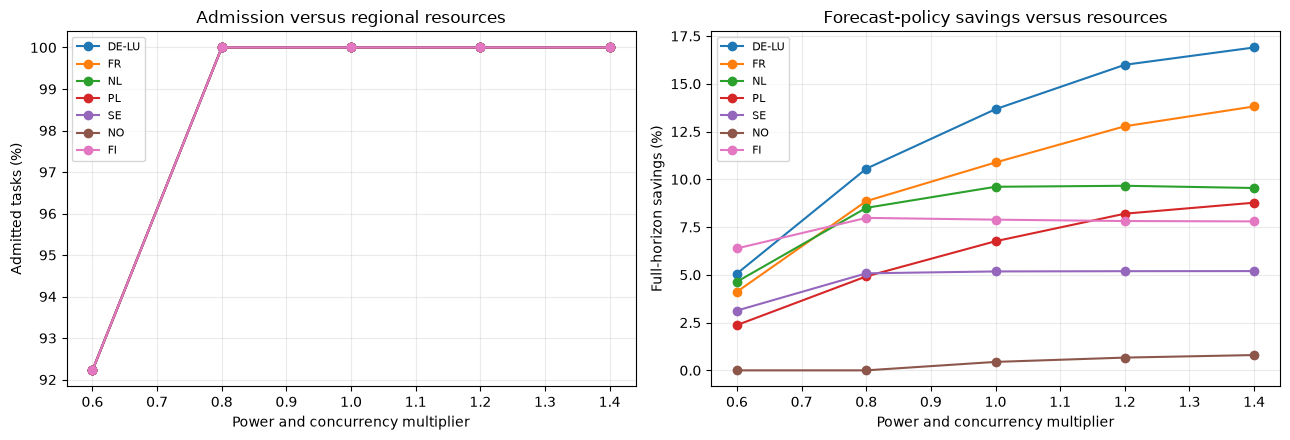

In [15]:
capacity_frames = []
if RUN_CAPACITY_SENSITIVITY:
    for region in regions:
        for scale in CAPACITY_SCALES:
            print(f"Capacity scenario: {region}, multiplier={scale:g}")
            result = run_scenario(region,DEMO_DATE,BASE_SEED,float(scale),"capacity_sensitivity")
            capacity_frames.append(result["metrics"].assign(experiment="capacity_sensitivity"))
capacity_results = pd.concat(capacity_frames,ignore_index=True) if capacity_frames else pd.DataFrame()
if not capacity_results.empty:
    display(capacity_results[["region","capacity_scale","policy","scheduled_jobs","excluded_jobs",
        "admission_rate_pct","target_savings_pct","full_horizon_savings_pct","selected_source"]])
    fig, axes = plt.subplots(1,2,figsize=(13,4.5))
    for region in regions:
        subset = capacity_results[(capacity_results["region"]==region)&(capacity_results["policy"]==POLICY_FORECAST)].sort_values("capacity_scale")
        axes[0].plot(subset["capacity_scale"],subset["admission_rate_pct"],marker="o",label=region)
        axes[1].plot(subset["capacity_scale"],subset["full_horizon_savings_pct"],marker="o",label=region)
    axes[0].set(xlabel="Power and concurrency multiplier",ylabel="Admitted tasks (%)",title="Admission versus regional resources")
    axes[1].set(xlabel="Power and concurrency multiplier",ylabel="Full-horizon savings (%)",title="Forecast-policy savings versus resources")
    for ax in axes: ax.legend(fontsize=8); ax.grid(alpha=.25)
    finish_figure("12_capacity_sensitivity")
else:
    print("Capacity sensitivity disabled.")

## 16. Multi-day and multi-seed robustness experiments

Use identical common dates and seeds across regions. Demonstration-day robustness varies the workload seed while holding grid conditions fixed. The multi-day experiment varies the selected dates and configured seeds. Scenarios already solved by another section are reused. Mean per-scenario percentage savings and pooled emissions-weighted savings are reported separately; pooled totals summarize scenarios and are not a claim of continuous multi-day operation.

Multi-day scenario: DE-LU, 2026-01-11, seed=42
Multi-day scenario: FR, 2026-01-11, seed=42
Multi-day scenario: NL, 2026-01-11, seed=42
Multi-day scenario: PL, 2026-01-11, seed=42
Multi-day scenario: SE, 2026-01-11, seed=42
Multi-day scenario: NO, 2026-01-11, seed=42
Multi-day scenario: FI, 2026-01-11, seed=42
Multi-day scenario: DE-LU, 2026-05-27, seed=42
Multi-day scenario: FR, 2026-05-27, seed=42
Multi-day scenario: NL, 2026-05-27, seed=42
Multi-day scenario: PL, 2026-05-27, seed=42
Multi-day scenario: SE, 2026-05-27, seed=42
Multi-day scenario: NO, 2026-05-27, seed=42
Multi-day scenario: FI, 2026-05-27, seed=42
Multi-day scenario: DE-LU, 2026-10-08, seed=42
Multi-day scenario: FR, 2026-10-08, seed=42
Multi-day scenario: NL, 2026-10-08, seed=42
Multi-day scenario: PL, 2026-10-08, seed=42
Multi-day scenario: SE, 2026-10-08, seed=42
Multi-day scenario: NO, 2026-10-08, seed=42
Multi-day scenario: FI, 2026-10-08, seed=42
Robustness scenario: DE-LU, seed=41
Robustness scenario: FR, seed=4

,region,policy,scenarios,mean_target_savings_pct,std_target_savings_pct,mean_full_savings_pct,std_full_savings_pct,min_full_savings_pct,max_full_savings_pct,mean_wait_hours,mean_admission_pct,total_excluded_jobs,solver_reference_selections,total_full_emissions_kg,total_full_savings_kg,pooled_full_savings_pct
0,DE-LU,Carbon-unaware baseline,3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,100.0000,0,0,"10,824.6799",0.0000,0.0000
1,DE-LU,Retrospective MILP benchmark,3,2.7100,3.8506,13.3232,8.9039,3.4306,20.6948,3.6088,100.0000,0,0,"9,478.3872","1,346.2927",12.4373
2,DE-LU,Rolling AR forecast MILP,3,3.8723,13.9068,11.9185,8.9907,2.1801,19.9030,2.9911,100.0000,0,0,"9,637.9475","1,186.7323",10.9632
3,FI,Carbon-unaware baseline,3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,100.0000,0,0,"2,438.0917",0.0000,0.0000
4,FI,Retrospective MILP benchmark,3,10.6454,14.1070,4.4521,3.8238,1.0395,8.5847,2.9015,100.0000,0,0,"2,344.8859",93.2058,3.8229
5,FI,Rolling AR forecast MILP,3,10.6732,13.7051,2.9510,4.3005,0.0219,7.8882,1.2319,100.0000,0,0,"2,377.6053",60.4864,2.4809
6,FR,Carbon-unaware baseline,3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,100.0000,0,0,"1,313.4030",0.0000,0.0000
7,FR,Retrospective MILP benchmark,3,8.2962,3.2926,10.4797,5.1301,6.0924,16.1204,3.1287,100.0000,0,0,"1,170.3955",143.0075,10.8883
8,FR,Rolling AR forecast MILP,3,7.7223,10.0979,6.4367,3.9212,3.4694,10.8822,2.1769,100.0000,0,0,"1,228.6434",84.7596,6.4534
9,NL,Carbon-unaware baseline,3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,100.0000,0,0,"14,524.5803",0.0000,0.0000


,region,policy,scenarios,mean_target_savings_pct,std_target_savings_pct,mean_full_savings_pct,std_full_savings_pct,min_full_savings_pct,max_full_savings_pct,mean_wait_hours,mean_admission_pct,total_excluded_jobs,solver_reference_selections,total_full_emissions_kg,total_full_savings_kg,pooled_full_savings_pct
0,DE-LU,Carbon-unaware baseline,3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,100.0000,0,0,"12,214.8437",0.0000,0.0000
1,DE-LU,Retrospective MILP benchmark,3,2.0586,1.3113,16.3385,0.4336,15.8442,16.6548,4.4807,100.0000,0,0,"10,218.6798","1,996.1639",16.3421
2,DE-LU,Rolling AR forecast MILP,3,-3.9414,1.3471,14.0258,0.3132,13.6724,14.2688,2.9937,100.0000,0,0,"10,501.3119","1,713.5318",14.0283
3,FI,Carbon-unaware baseline,3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,100.0000,0,0,"2,123.1070",0.0000,0.0000
4,FI,Retrospective MILP benchmark,3,26.2648,0.3995,8.6041,0.0675,8.5485,8.6792,2.4091,100.0000,0,0,"1,940.4380",182.6690,8.6039
5,FI,Rolling AR forecast MILP,3,25.8944,0.3443,7.9323,0.0818,7.8819,8.0267,2.2229,100.0000,0,0,"1,954.6988",168.4081,7.9322
6,FR,Carbon-unaware baseline,3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,100.0000,0,0,"1,403.6945",0.0000,0.0000
7,FR,Retrospective MILP benchmark,3,11.2853,1.3707,15.9670,0.1744,15.7772,16.1204,3.6867,100.0000,0,0,"1,179.5634",224.1311,15.9672
8,FR,Rolling AR forecast MILP,3,17.2479,1.2979,11.3718,0.4267,10.8822,11.6643,2.1514,100.0000,0,0,"1,244.0444",159.6501,11.3736
9,NL,Carbon-unaware baseline,3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,100.0000,0,0,"14,694.0012",0.0000,0.0000


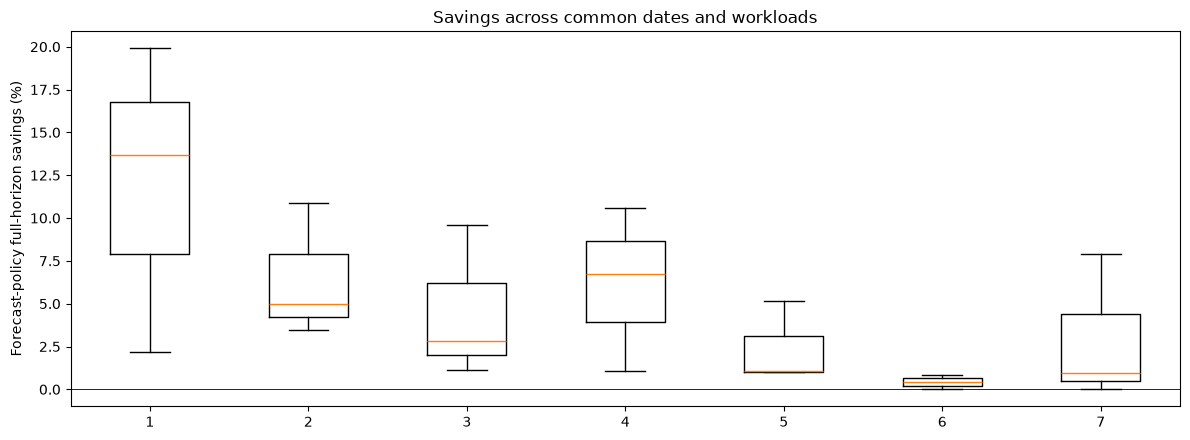

In [16]:
experiment_frames, robustness_frames = [], []
if RUN_MULTI_DAY:
    for date_string in evaluation_dates:
        for seed in WORKLOAD_SEEDS:
            for region in regions:
                print(f"Multi-day scenario: {region}, {date_string}, seed={seed}")
                result = run_scenario(region,date_string,int(seed),1.,"multi_day")
                experiment_frames.append(result["metrics"].assign(experiment="multi_day"))
if RUN_ROBUSTNESS:
    for seed in ROBUSTNESS_SEEDS:
        for region in regions:
            print(f"Robustness scenario: {region}, seed={seed}")
            result = run_scenario(region,DEMO_DATE,int(seed),1.,"robustness")
            robustness_frames.append(result["metrics"].assign(experiment="robustness"))
experiment_results = pd.concat(experiment_frames,ignore_index=True) if experiment_frames else pd.DataFrame()
robustness_results = pd.concat(robustness_frames,ignore_index=True) if robustness_frames else pd.DataFrame()

def summarize_experiments(frame):
    if frame.empty:
        return pd.DataFrame()
    out = frame.groupby(["region","policy"]).agg(
        scenarios=("date","size"),mean_target_savings_pct=("target_savings_pct","mean"),
        std_target_savings_pct=("target_savings_pct","std"),
        mean_full_savings_pct=("full_horizon_savings_pct","mean"),
        std_full_savings_pct=("full_horizon_savings_pct","std"),
        min_full_savings_pct=("full_horizon_savings_pct","min"),max_full_savings_pct=("full_horizon_savings_pct","max"),
        mean_wait_hours=("mean_wait_hours","mean"),mean_admission_pct=("admission_rate_pct","mean"),
        total_excluded_jobs=("excluded_jobs","sum"),solver_reference_selections=("used_reference","sum"),
        total_full_emissions_kg=("full_horizon_emissions_kgCO2eq","sum"),
        total_full_savings_kg=("full_horizon_savings_kg","sum")).reset_index()
    denom = out["total_full_emissions_kg"]+out["total_full_savings_kg"]
    out["pooled_full_savings_pct"] = 100*out["total_full_savings_kg"]/denom.replace(0,np.nan)
    return out
experiment_summary = summarize_experiments(experiment_results)
robustness_summary = summarize_experiments(robustness_results)
display(experiment_summary)
display(robustness_summary)
if not experiment_results.empty:
    fig, ax = plt.subplots(figsize=(12,4.5))
    values = [experiment_results[(experiment_results["region"]==r)&
              (experiment_results["policy"]==POLICY_FORECAST)]["full_horizon_savings_pct"].dropna().to_numpy() for r in regions]
    ax.boxplot(values,label=regions)
    ax.set(ylabel="Forecast-policy full-horizon savings (%)",title="Savings across common dates and workloads")
    ax.axhline(0,color="black",lw=.6)
    finish_figure("13_multi_day_savings_distribution")

## 17. Export results, schedules, and reproducibility settings

Exports include aligned regional target-day signals, coverage and EDA, all policy metrics, rolling forecast errors, capacity and robustness results, solver provenance, exclusion logs, and per-scenario task schedules. The settings JSON records experimental assumptions and enabled experiments. Each generated task and accepted schedule is identified by region, date, seed, and capacity multiplier. Empty optional results are exported with a status column. Exclusions are recorded once per unique cached scenario.

In [17]:
solver_log = pd.DataFrame(MILP_SOLVE_LOG)
forecast_fit_log = pd.DataFrame(FORECAST_FIT_LOG)
rolling_forecast_predictions = pd.concat(FORECAST_PREDICTION_FRAMES,ignore_index=True)
exclusion_columns = ["task_id","release_slot","duration_slots","power_kw","deadline_slot","failure_reason",
                     "region","date","workload_seed","capacity_scale","experiment"]
deadline_violation_log = pd.concat(EXCLUSION_FRAMES,ignore_index=True) if EXCLUSION_FRAMES else pd.DataFrame(columns=exclusion_columns)
exports = {
    "regional_carbon_intensity_24h.csv":ci_day,"regional_carbon_intensity_statistics.csv":regional_stats.reset_index(names="region"),
    "load_diagnostics.csv":load_diagnostics.reset_index(),"regional_coverage.csv":coverage_report.reset_index(names="region"),
    "daily_carbon_coverage.csv":day_stats,"datacenter_configuration.csv":dc_config.reset_index(),
    "demo_policy_metrics.csv":metrics_table,"carbon_savings_vs_baseline.csv":savings_table,
    "forecast_diagnostics.csv":forecast_diagnostics,
    "rolling_forecast_lead_metrics_demo.csv":forecast_lead_metrics,
    "rolling_forecast_fit_log.csv":forecast_fit_log,
    "rolling_forecast_predictions_all_scenarios.csv":rolling_forecast_predictions,"capacity_sensitivity.csv":capacity_results,
    "multi_day_results.csv":experiment_results,"multi_day_summary.csv":experiment_summary,
    "multi_seed_robustness.csv":robustness_results,"multi_seed_summary.csv":robustness_summary,
    "baseline_exclusion_log.csv":deadline_violation_log,"milp_solver_log.csv":solver_log,
}
for filename,frame in exports.items():
    if len(frame.columns)==0:
        frame = pd.DataFrame(columns=["status_optional_experiment_disabled"])
    frame.to_csv(OUTPUT_DIR/filename,index=False)
pearson_corr.to_csv(OUTPUT_DIR/"regional_ci_pearson_correlation.csv")
spearman_corr.to_csv(OUTPUT_DIR/"regional_ci_spearman_correlation.csv")
settings = {"regions":regions,"regional_files":{r:str(p) for r,p in REGION_FILES.items()},
    "target_date":DEMO_DATE,"evaluation_dates":evaluation_dates,"local_timezone":LOCAL_TIMEZONE,
    "slot_hours":SLOT_HOURS,"arrival_slots":ARRIVAL_SLOTS,"horizon_slots":HORIZON_SLOTS,
    "target_window_slots":[TARGET_START_SLOT,TARGET_END_SLOT],"n_jobs_per_region":N_JOBS,
    "base_seed":BASE_SEED,"workload_seeds":WORKLOAD_SEEDS,"robustness_seeds":ROBUSTNESS_SEEDS,
    "duration_values_slots":DURATION_VALUES,"duration_probabilities":DURATION_PROBABILITIES,
    "power_values_kw":POWER_VALUES_KW,"power_probabilities":POWER_PROBABILITIES,
    "deadline_hours":[MIN_DEADLINE_HOURS,MAX_DEADLINE_HOURS],"capacity_scales":CAPACITY_SCALES,
    "forecast_model":"recursive_autoregressive_ridge",
    "forecast_update_slots":FORECAST_UPDATE_SLOTS,"forecast_train_days":FORECAST_TRAIN_DAYS,
    "forecast_min_history_days":FORECAST_MIN_HISTORY_DAYS,"forecast_lags":FORECAST_LAGS,
    "forecast_min_train_samples":FORECAST_MIN_TRAIN_SAMPLES,"forecast_ridge_alpha":FORECAST_RIDGE_ALPHA,
    "forecast_clip_multiplier":FORECAST_CLIP_MULTIPLIER,
    "forecast_cost_vintage":"latest_issue_at_task_release",
    "milp_time_limit_seconds":MILP_TIME_LIMIT_SECONDS,"milp_relative_gap":MILP_RELATIVE_GAP,
    "run_multi_day":RUN_MULTI_DAY,"run_robustness":RUN_ROBUSTNESS,
    "run_capacity_sensitivity":RUN_CAPACITY_SENSITIVITY,
    "numpy_version":np.__version__,"pandas_version":pd.__version__}
(OUTPUT_DIR/"experiment_settings.json").write_text(json.dumps(settings,indent=2),encoding="utf-8")
schedule_dir = OUTPUT_DIR/"schedules"
schedule_dir.mkdir(exist_ok=True)
for (region,date_string,seed,scale),result in SCENARIO_CACHE.items():
    token = f"{region}_{date_string}_seed{seed}_cap{scale:g}"
    result["generated_tasks"].to_csv(schedule_dir/f"workload_{token}.csv",index=False)
    for policy,table in result["schedules"].items():
        safe = re.sub(r"[^A-Za-z0-9]+","_",policy).strip("_").lower()
        table.assign(region=region,date=date_string,workload_seed=seed,capacity_scale=scale,policy=policy).to_csv(
            schedule_dir/f"schedule_{token}_{safe}.csv",index=False)
print(f"Exported {len(SCENARIO_CACHE)} unique regional scenarios to {OUTPUT_DIR.resolve()}")
print(f"MILP solves: {len(solver_log)}; selected reference schedules: {int(solver_log['used_reference'].sum()) if len(solver_log) else 0}")
print(f"Excluded-task records across unique scenarios: {len(deadline_violation_log)}")

Exported 63 unique regional scenarios to C:\Games\Univer\teza_master\evaluation_of_spatio-temporal_task_scheduling\temporal_multi_region_outputs
MILP solves: 126; selected reference schedules: 4
Excluded-task records across unique scenarios: 490


## 18. Interpretation and limitations for the report

Assess temporal savings within each region before comparing regional performance. A low-intensity region may offer low absolute workload emissions but little additional temporal-shifting benefit. Strong intraday variation can offer more flexibility, subject to deadlines, power and concurrency. Cross-region differences here reflect separate temporal experiments, not spatial workload routing.

Report both middle-day and complete-workload emissions. The middle-day metric is intentionally a fixed calendar window; a decrease is not by itself evidence of a reduction in total emissions. Full-horizon task energy is invariant within a common accepted set, whereas middle-day energy can change as execution crosses the window boundary.

The workload is synthetic, arrivals span the first 48 hours, and the preceding day begins with no earlier backlog. Baseline admission filtering may exclude tasks another admission/scheduling policy could accommodate. Exclusion rates use all generated tasks; accepted-schedule deadline violations are different quantities. Resource sensitivity scales power and concurrency together and cannot isolate their separate effects.

Both MILP policies know future task arrivals. The rolling forecast policy uses a separate causal forecast vintage for each task's release: training targets and observed feature history strictly precede that vintage's issue time. Predictions extend recursively through the task's deadline and are not replaced by future revisions during optimization. This prevents carbon-observation leakage, but the all-arrivals MILP is still an offline experiment rather than an online rolling scheduler. A deployable rolling controller would also need to handle unknown arrivals and preserve committed/running decisions. The observed-intensity benchmark uses perfect future carbon information. Solver time limits, gaps and reference selections must accompany optimization claims; exact optimality is not assumed. Forecast horizon error, training history availability, and the fixed model configuration limit generalization; tune parameters using a separate chronological validation period rather than the reported test days.

The carbon signal is generation-weighted lifecycle average intensity, not marginal avoided emissions. Task power is constant and independent of region. Cooling/PUE, idle power, startup costs, hardware differences, user latency, data residency, network-transfer overhead and spatial relocation are outside this temporal-only model. Multi-seed robustness uses one fixed day; multi-day results are limited to common complete dates and the selected workload assumptions.

For the report, use Section 4 figures for regional context, Section 11 tables and Section 13 plots for policy outcomes, Section 15 for capacity effects, and Section 16 for workload/day variability. Always report the generated and accepted counts, target and full-horizon savings, waiting times, resource constraints, forecast errors, and solver status. Do not describe a time-limited benchmark as a proven oracle.